1st annotator: Ashabul Yamin Tuhin_ID:C233188_c233188@ugrad.iiuc.ac.bd(ashabulyamintuhin@gmail.com)

2nd annotator: Jamil_Siddique Chowdhury_Versity ID:C233166_c233166@ugrad.iiuc.ac.bd

In [1]:
import pandas as pd
from sklearn.metrics import cohen_kappa_score

df = pd.read_excel('./Annotation.xlsx', sheet_name="Sheet1")

df = df[["label", "Jamil_lebel"]].dropna()

df["label"] = df["label"].astype(str).str.strip().str.title()
df["Jamil_lebel"] = df["Jamil_lebel"].astype(str).str.strip().str.title()



kappa = cohen_kappa_score(df["label"], df["Jamil_lebel"])

print("N =", len(df))
print("Cohen's kappa =", kappa)

cm = pd.crosstab(
    df["label"],
    df["Jamil_lebel"],
    margins=True,
    margins_name="Total"
)
print(cm)

cm.to_excel("confusion_matrix.xlsx")

N = 5140
Cohen's kappa = 0.7858288328267302
Jamil_lebel     Gender Abusive  Geopolitical  Non-Abusive  Personal  \
label                                                                 
Gender Abusive              25             1            0         6   
Geopolitical                 0           298          172        24   
Non-Abusive                  1            15         1439        40   
Personal                     2            15          104      1461   
Political                    0             7          260         9   
Religious                    0             1           55        25   
Total                       28           337         2030      1565   

Jamil_lebel     Political  Religious  Total  
label                                        
Gender Abusive          1          0     33  
Geopolitical           24          0    518  
Non-Abusive            13          1   1509  
Personal                1          1   1584  
Political             946          2   1

INTER-ANNOTATOR RELIABILITY REPORT
Samples analysed                 : 5,140
Number of categories             : 6
Observed agreement               : 0.8426 (84.26%)
Balanced accuracy                : 0.7629
Macro F1-score                   : 0.8072
Multiclass Cohen's kappa         : 0.7858
Bootstrap 95% CI for kappa       : [0.7722, 0.7990]
Interpretation                   : Substantial agreement

Classification report:
                precision    recall  f1-score   support

Gender Abusive      0.893     0.758     0.820        33
  Geopolitical      0.884     0.575     0.697       518
   Non-Abusive      0.709     0.954     0.813      1509
      Personal      0.934     0.922     0.928      1584
     Political      0.933     0.773     0.845      1224
     Religious      0.976     0.596     0.740       272

      accuracy                          0.843      5140
     macro avg      0.888     0.763     0.807      5140
  weighted avg      0.864     0.843     0.841      5140


Binary one-vs

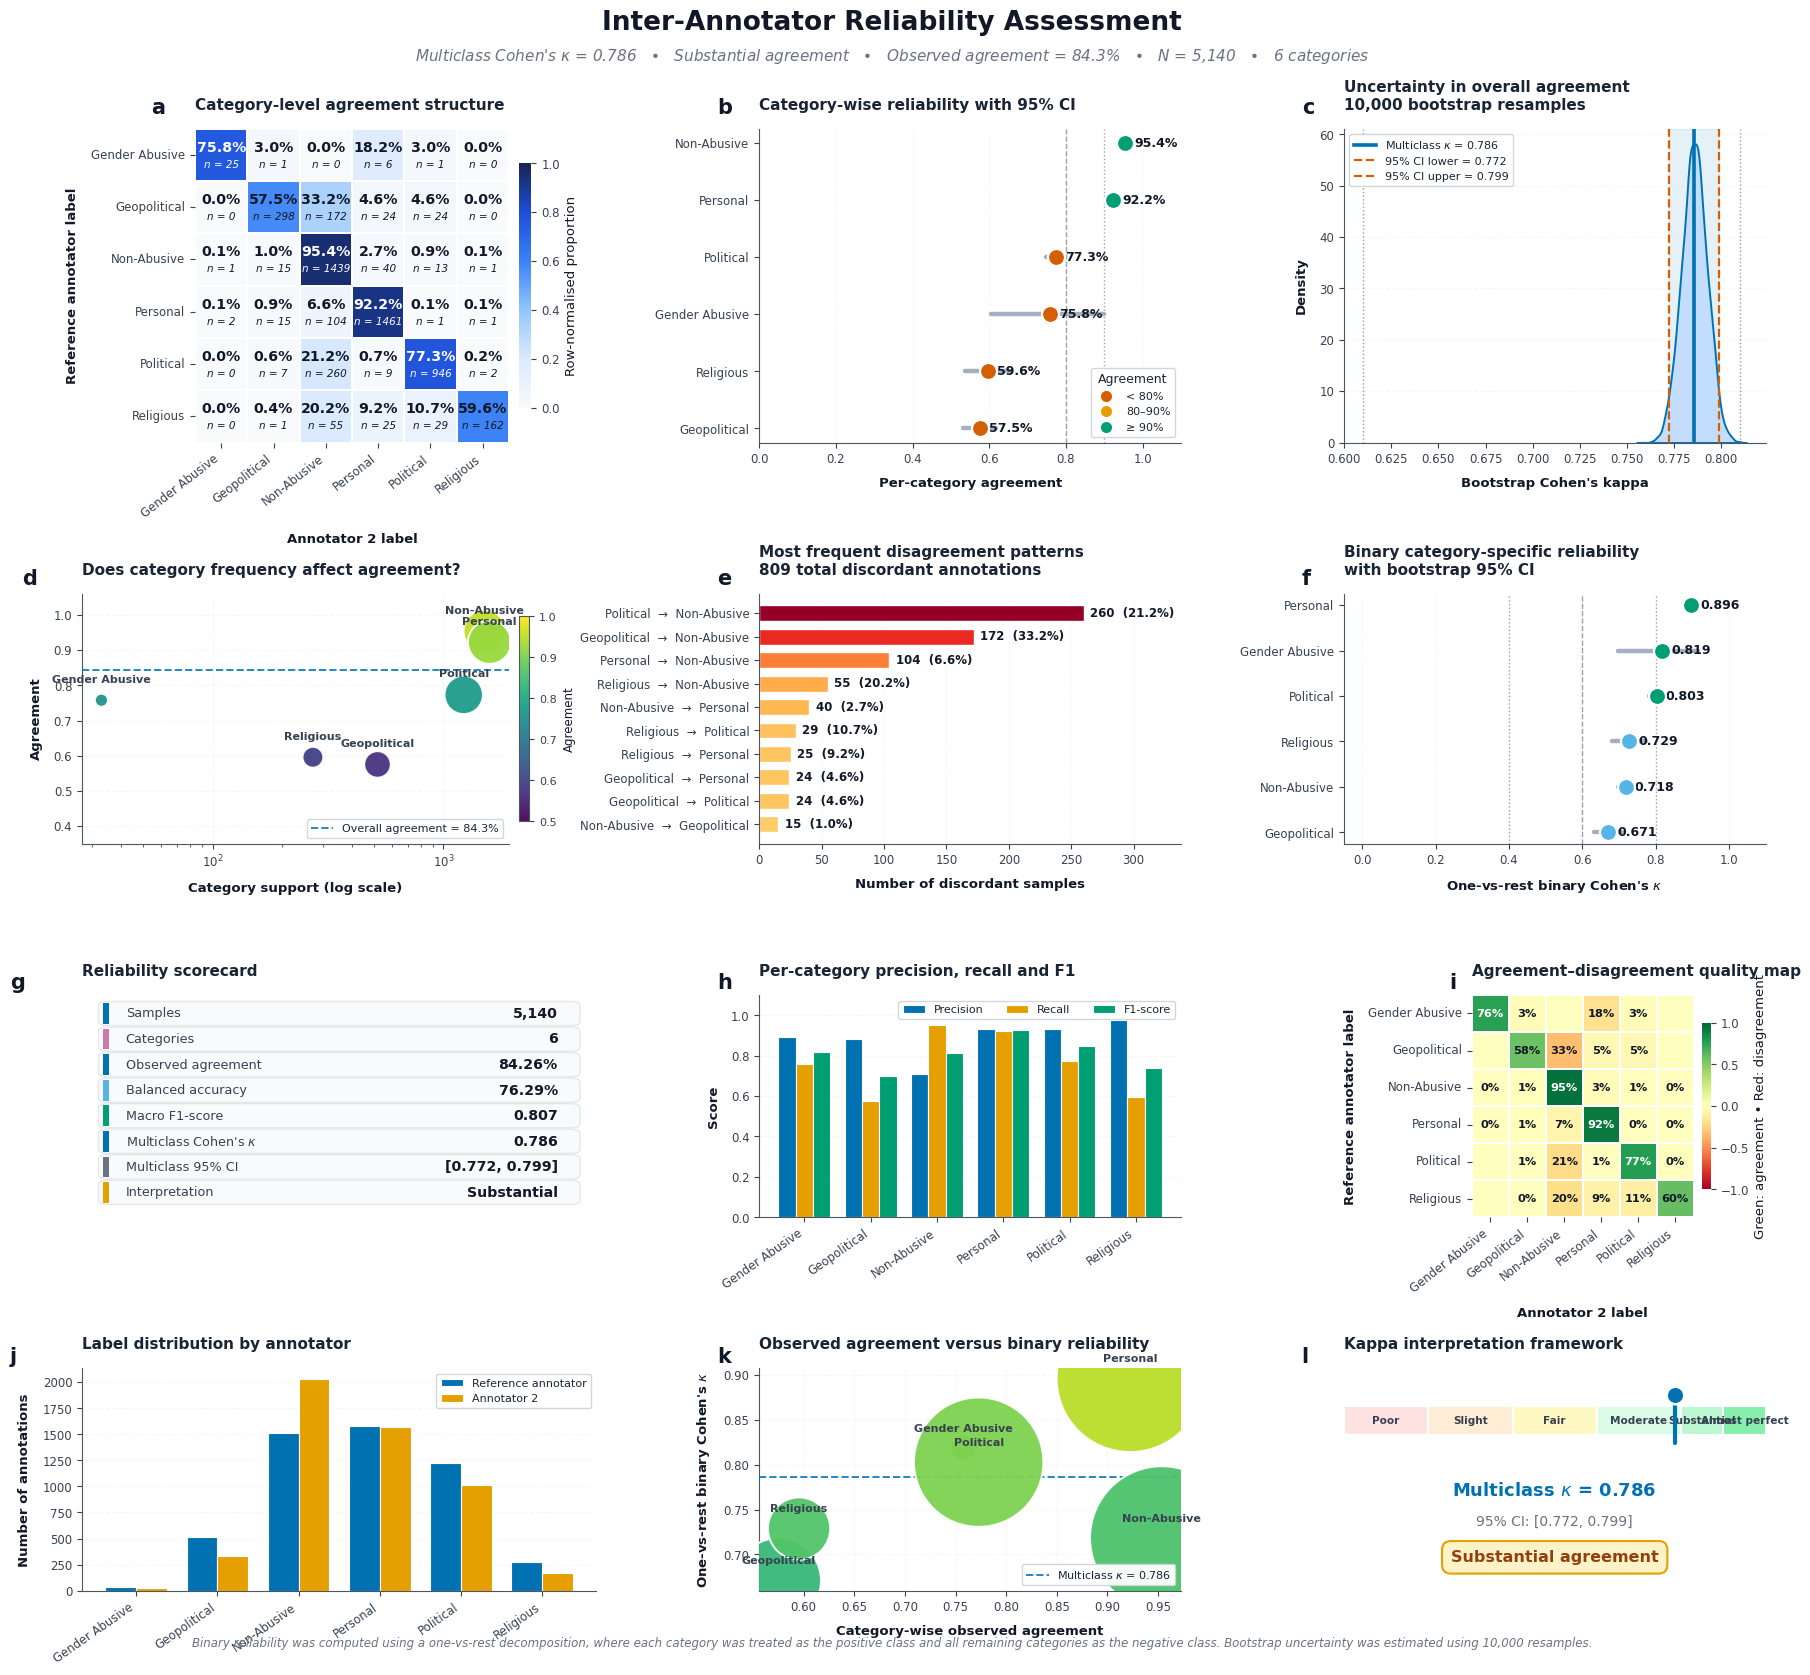


Saved files:
- inter_annotator_reliability_dashboard.png
- inter_annotator_reliability_dashboard.pdf
- inter_annotator_reliability_dashboard.svg
- inter_annotator_reliability_full_results.xlsx


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.lines import Line2D
import seaborn as sns

from sklearn.metrics import (
    cohen_kappa_score,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
)


plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "axes.edgecolor": "#4B5563",
    "axes.labelcolor": "#111827",
    "xtick.color": "#374151",
    "ytick.color": "#374151",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

C = {
    "blue": "#0072B2",
    "sky": "#56B4E9",
    "orange": "#E69F00",
    "green": "#009E73",
    "red": "#D55E00",
    "purple": "#CC79A7",
    "yellow": "#F0E442",
    "ink": "#111827",
    "muted": "#6B7280",
    "grid": "#E5E7EB",
    "light": "#F8FAFC",
}


df = pd.read_excel("./Annotation.xlsx", sheet_name="Sheet1")
df = df[["label", "Jamil_lebel"]].dropna().copy()

df["label"] = df["label"].astype(str).str.strip().str.title()
df["Jamil_lebel"] = df["Jamil_lebel"].astype(str).str.strip().str.title()

y_true = df["label"].to_numpy()
y_pred = df["Jamil_lebel"].to_numpy()
labels = sorted(set(y_true) | set(y_pred))
n_classes = len(labels)
n_samples = len(df)


kappa = cohen_kappa_score(y_true, y_pred)
accuracy = accuracy_score(y_true, y_pred)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    labels=labels,
    zero_division=0,
)

rng = np.random.default_rng(42)
n_boot = 10000

boot_kappas = []
boot_class_agreement = {label: [] for label in labels}
boot_binary_kappa = {label: [] for label in labels}

for _ in range(n_boot):
    idx = rng.integers(0, n_samples, size=n_samples)
    yt, yp = y_true[idx], y_pred[idx]

    if len(set(yt)) < 2 or len(set(yp)) < 2:
        continue

    boot_kappas.append(cohen_kappa_score(yt, yp))

    cm_b = confusion_matrix(yt, yp, labels=labels)
    row_sum = cm_b.sum(axis=1)

    for i, label in enumerate(labels):
        if row_sum[i] > 0:
            boot_class_agreement[label].append(cm_b[i, i] / row_sum[i])

        yt_bin = (yt == label).astype(int)
        yp_bin = (yp == label).astype(int)

        if len(np.unique(yt_bin)) > 1 and len(np.unique(yp_bin)) > 1:
            boot_binary_kappa[label].append(
                cohen_kappa_score(yt_bin, yp_bin)
            )

boot_kappas = np.asarray(boot_kappas)
kappa_ci_low, kappa_ci_high = np.percentile(boot_kappas, [2.5, 97.5])


def kappa_interpretation(k):
    if k < 0.00:
        return "Poor"
    if k < 0.21:
        return "Slight"
    if k < 0.41:
        return "Fair"
    if k < 0.61:
        return "Moderate"
    if k < 0.81:
        return "Substantial"
    return "Almost perfect"


interpretation = kappa_interpretation(kappa)

print("=" * 78)
print("INTER-ANNOTATOR RELIABILITY REPORT")
print("=" * 78)
print(f"Samples analysed                 : {n_samples:,}")
print(f"Number of categories             : {n_classes}")
print(f"Observed agreement               : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Balanced accuracy                : {balanced_acc:.4f}")
print(f"Macro F1-score                   : {macro_f1:.4f}")
print(f"Multiclass Cohen's kappa         : {kappa:.4f}")
print(f"Bootstrap 95% CI for kappa       : [{kappa_ci_low:.4f}, {kappa_ci_high:.4f}]")
print(f"Interpretation                   : {interpretation} agreement")
print("\nClassification report:")
print(
    classification_report(
        y_true, y_pred,
        labels=labels,
        digits=3,
        zero_division=0,
    )
)


cm = confusion_matrix(y_true, y_pred, labels=labels)
cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)

cm_df = pd.DataFrame(cm, index=labels, columns=labels)
cm_norm_df = pd.DataFrame(cm_norm, index=labels, columns=labels)

error_matrix = cm.copy()
np.fill_diagonal(error_matrix, 0)
error_total = int(error_matrix.sum())

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred,
    labels=labels,
    zero_division=0,
)

class_ci = {}
for label in labels:
    vals = np.asarray(boot_class_agreement[label])
    class_ci[label] = (
        np.percentile(vals, 2.5) if len(vals) else np.nan,
        np.percentile(vals, 97.5) if len(vals) else np.nan,
    )

per_class = pd.DataFrame({
    "Category": labels,
    "Support": support,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Agreement": np.diag(cm) / np.maximum(cm.sum(axis=1), 1),
    "Agreement_CI_low": [class_ci[x][0] for x in labels],
    "Agreement_CI_high": [class_ci[x][1] for x in labels],
})


binary_rows = []

for label in labels:
    yt_bin = (y_true == label).astype(int)
    yp_bin = (y_pred == label).astype(int)

    valid = (
        len(np.unique(yt_bin)) > 1 and
        len(np.unique(yp_bin)) > 1
    )

    binary_kappa_value = (
        cohen_kappa_score(yt_bin, yp_bin) if valid else np.nan
    )

    binary_agreement = np.mean(yt_bin == yp_bin)

    boot_vals = np.asarray(boot_binary_kappa[label])

    if len(boot_vals):
        bin_ci_low, bin_ci_high = np.percentile(boot_vals, [2.5, 97.5])
    else:
        bin_ci_low, bin_ci_high = np.nan, np.nan

    binary_rows.append({
        "Category": label,
        "Binary task": f"{label} vs Rest",
        "Positive support": int(yt_bin.sum()),
        "Negative support": int(n_samples - yt_bin.sum()),
        "Binary agreement": binary_agreement,
        "Binary Cohen's kappa": binary_kappa_value,
        "Binary kappa CI lower": bin_ci_low,
        "Binary kappa CI upper": bin_ci_high,
    })

binary_kappa_df = pd.DataFrame(binary_rows)

per_class = per_class.merge(
    binary_kappa_df[
        [
            "Category",
            "Binary Cohen's kappa",
            "Binary kappa CI lower",
            "Binary kappa CI upper",
        ]
    ],
    on="Category",
    how="left",
)

print("\nBinary one-vs-rest Cohen's kappa:")
print(binary_kappa_df.to_string(index=False))

# ------------------------------------------------------------
# 6. Create dashboard
# ------------------------------------------------------------
fig = plt.figure(figsize=(18.5, 17.0), facecolor="white")

gs = gridspec.GridSpec(
    4, 3,
    width_ratios=[1.22, 1.00, 1.00],
    height_ratios=[1.13, 0.90, 0.80, 0.80],
    left=0.062,
    right=0.972,
    top=0.905,
    bottom=0.045,
    hspace=0.60,
    wspace=0.36,
)

# ------------------------------------------------------------
# PANEL A — Agreement matrix
# ------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

matrix_cmap = LinearSegmentedColormap.from_list(
    "professional_blue",
    ["#F8FAFC", "#DBEAFE", "#93C5FD", "#3B82F6", "#1D4ED8", "#172554"],
)

sns.heatmap(
    cm_norm_df,
    ax=ax1,
    cmap=matrix_cmap,
    vmin=0,
    vmax=1,
    square=True,
    linewidths=1.2,
    linecolor="white",
    cbar_kws={
        "label": "Row-normalised proportion",
        "shrink": 0.78,
        "pad": 0.02,
    },
)

for i in range(n_classes):
    for j in range(n_classes):
        prop = cm_norm[i, j]
        count = cm[i, j]
        text_color = "white" if prop > 0.60 else "#111827"

        ax1.text(
            j + 0.5, i + 0.36,
            f"{prop * 100:.1f}%",
            ha="center", va="center",
            fontsize=10.2, fontweight="bold",
            color=text_color,
        )

        ax1.text(
            j + 0.5, i + 0.68,
            f"n = {count}",
            ha="center", va="center",
            fontsize=7.5, style="italic",
            color=text_color,
        )

ax1.set_xlabel("Annotator 2 label", fontweight="bold", labelpad=9)
ax1.set_ylabel("Reference annotator label", fontweight="bold", labelpad=9)
ax1.set_title("Category-level agreement structure", loc="left", pad=14)
ax1.set_xticklabels(labels, rotation=38, ha="right")
ax1.set_yticklabels(labels, rotation=0)

# ------------------------------------------------------------
# PANEL B — Per-class agreement with CI
# ------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

order = np.argsort(per_class["Agreement"].to_numpy())
sorted_df = per_class.iloc[order].reset_index(drop=True)
ypos = np.arange(len(sorted_df))

for y, row in sorted_df.iterrows():
    lo = row["Agreement_CI_low"]
    hi = row["Agreement_CI_high"]

    if not np.isnan(lo):
        ax2.plot(
            [lo, hi], [y, y],
            color="#94A3B8",
            linewidth=3.2,
            solid_capstyle="round",
            alpha=0.85,
            zorder=2,
        )

    value = row["Agreement"]
    color = (
        C["red"] if value < 0.80 else
        C["orange"] if value < 0.90 else
        C["green"]
    )

    ax2.scatter(
        value, y,
        s=150,
        color=color,
        edgecolor="white",
        linewidth=1.6,
        zorder=4,
    )

    ax2.text(
        min(value + 0.025, 1.04), y,
        f"{value * 100:.1f}%",
        va="center", ha="left",
        fontsize=9, fontweight="bold",
        color=C["ink"],
    )

for threshold, ls in [(0.80, "--"), (0.90, ":")]:
    ax2.axvline(
        threshold,
        color=C["muted"],
        linestyle=ls,
        linewidth=1,
        alpha=0.65,
        zorder=1,
    )

ax2.set_yticks(ypos)
ax2.set_yticklabels(sorted_df["Category"])
ax2.set_xlim(0, 1.10)
ax2.set_xlabel("Per-category agreement", fontweight="bold", labelpad=8)
ax2.set_title("Category-wise reliability with 95% CI", loc="left", pad=14)
ax2.grid(axis="x", linestyle="--", alpha=0.30, color=C["grid"])
ax2.set_axisbelow(True)
sns.despine(ax=ax2)

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=C["red"],
           markeredgecolor="white", markersize=9, label="< 80%"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=C["orange"],
           markeredgecolor="white", markersize=9, label="80–90%"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=C["green"],
           markeredgecolor="white", markersize=9, label="≥ 90%"),
]

ax2.legend(
    handles=legend_handles,
    title="Agreement",
    loc="lower right",
    frameon=True,
    framealpha=0.95,
    edgecolor="#D1D5DB",
)

# ------------------------------------------------------------
# PANEL C — Bootstrap multiclass kappa
# ------------------------------------------------------------
ax3 = fig.add_subplot(gs[0, 2])

sns.kdeplot(
    boot_kappas,
    ax=ax3,
    fill=True,
    color="#BFDBFE",
    edgecolor=C["blue"],
    linewidth=1.4,
    alpha=0.90,
)

ax3.axvspan(
    kappa_ci_low, kappa_ci_high,
    color=C["blue"], alpha=0.10, zorder=0,
)

ax3.axvline(
    kappa, color=C["blue"],
    linewidth=2.6, zorder=5,
    label=rf"Multiclass $\kappa$ = {kappa:.3f}",
)

ax3.axvline(
    kappa_ci_low, color=C["red"],
    linestyle="--", linewidth=1.6, zorder=4,
    label=f"95% CI lower = {kappa_ci_low:.3f}",
)

ax3.axvline(
    kappa_ci_high, color=C["red"],
    linestyle="--", linewidth=1.6, zorder=4,
    label=f"95% CI upper = {kappa_ci_high:.3f}",
)

for boundary in [0.61, 0.81]:
    ax3.axvline(
        boundary,
        color=C["muted"],
        linestyle=":",
        linewidth=1,
        alpha=0.70,
        zorder=1,
    )

ax3.set_xlabel("Bootstrap Cohen's kappa", fontweight="bold", labelpad=8)
ax3.set_ylabel("Density", fontweight="bold", labelpad=8)
ax3.set_title(
    f"Uncertainty in overall agreement\n{len(boot_kappas):,} bootstrap resamples",
    loc="left", pad=14,
)
ax3.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.95,
    edgecolor="#D1D5DB",
)
ax3.grid(axis="y", linestyle="--", alpha=0.30, color=C["grid"])
ax3.set_axisbelow(True)
sns.despine(ax=ax3)

# ------------------------------------------------------------
# PANEL D — Support vs agreement
# ------------------------------------------------------------
ax4 = fig.add_subplot(gs[1, 0])

bubble_sizes = 70 + 900 * (
    per_class["Support"] / per_class["Support"].max()
)

scatter = ax4.scatter(
    per_class["Support"],
    per_class["Agreement"],
    s=bubble_sizes,
    c=per_class["Agreement"],
    cmap="viridis",
    vmin=0.5,
    vmax=1.0,
    edgecolor="white",
    linewidth=1.4,
    alpha=0.95,
    zorder=3,
)

for _, row in per_class.iterrows():
    ax4.annotate(
        row["Category"],
        (row["Support"], row["Agreement"]),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold",
        color="#374151",
    )

ax4.axhline(
    accuracy,
    color=C["blue"],
    linestyle="--",
    linewidth=1.4,
    alpha=0.85,
    label=f"Overall agreement = {accuracy * 100:.1f}%",
)

ax4.set_xscale("log")
ax4.set_xlabel("Category support (log scale)", fontweight="bold", labelpad=8)
ax4.set_ylabel("Agreement", fontweight="bold", labelpad=8)
ax4.set_title("Does category frequency affect agreement?", loc="left", pad=14)
ax4.set_ylim(0.35, 1.06)
ax4.grid(True, linestyle="--", alpha=0.30, color=C["grid"])
ax4.set_axisbelow(True)
ax4.legend(
    loc="lower right",
    frameon=True,
    framealpha=0.95,
    edgecolor="#D1D5DB",
)
sns.despine(ax=ax4)

cbar = fig.colorbar(scatter, ax=ax4, pad=0.02, shrink=0.82)
cbar.set_label("Agreement", fontsize=8.5)
cbar.ax.tick_params(labelsize=8)

# ------------------------------------------------------------
# PANEL E — Top disagreement flows
# ------------------------------------------------------------
ax5 = fig.add_subplot(gs[1, 1])

error_pairs = []

for i, true_label in enumerate(labels):
    for j, pred_label in enumerate(labels):
        if i != j and error_matrix[i, j] > 0:
            error_pairs.append({
                "True": true_label,
                "Predicted": pred_label,
                "Count": int(error_matrix[i, j]),
                "Rate": error_matrix[i, j] / max(cm[i].sum(), 1),
            })

error_df = pd.DataFrame(error_pairs).sort_values(
    "Count", ascending=False
)

if len(error_df) == 0:
    ax5.axis("off")
    ax5.text(
        0.5, 0.5,
        "No systematic disagreement detected",
        ha="center", va="center",
        fontsize=12, fontweight="bold",
        color=C["green"],
    )
else:
    top_n = min(10, len(error_df))
    top_errors = error_df.head(top_n).iloc[::-1]

    pair_labels = [
        f"{row['True']}  →  {row['Predicted']}"
        for _, row in top_errors.iterrows()
    ]

    colors = plt.cm.YlOrRd(
        0.25 + 0.70 * (
            top_errors["Count"] / top_errors["Count"].max()
        )
    )

    ax5.barh(
        np.arange(top_n),
        top_errors["Count"],
        color=colors,
        edgecolor="white",
        linewidth=1,
        height=0.68,
    )

    for y, (_, row) in zip(np.arange(top_n), top_errors.iterrows()):
        ax5.text(
            row["Count"] + max(top_errors["Count"]) * 0.02,
            y,
            f"{int(row['Count'])}  ({row['Rate'] * 100:.1f}%)",
            va="center", ha="left",
            fontsize=8.5, fontweight="bold",
            color=C["ink"],
        )

    ax5.set_yticks(np.arange(top_n))
    ax5.set_yticklabels(pair_labels, fontsize=8.5)
    ax5.set_xlim(0, max(top_errors["Count"]) * 1.30)
    ax5.set_xlabel("Number of discordant samples", fontweight="bold", labelpad=8)
    ax5.set_title(
        f"Most frequent disagreement patterns\n{error_total:,} total discordant annotations",
        loc="left", pad=14,
    )
    ax5.grid(axis="x", linestyle="--", alpha=0.30, color=C["grid"])
    ax5.set_axisbelow(True)
    sns.despine(ax=ax5)

# ------------------------------------------------------------
# PANEL F — NEW: Binary one-vs-rest Cohen's kappa
# ------------------------------------------------------------
ax6 = fig.add_subplot(gs[1, 2])

binary_sorted = binary_kappa_df.sort_values(
    "Binary Cohen's kappa",
    ascending=True,
).reset_index(drop=True)

ypos_bin = np.arange(len(binary_sorted))

for y, row in binary_sorted.iterrows():
    lo = row["Binary kappa CI lower"]
    hi = row["Binary kappa CI upper"]

    if not np.isnan(lo):
        ax6.plot(
            [lo, hi], [y, y],
            color="#94A3B8",
            linewidth=3.2,
            solid_capstyle="round",
            alpha=0.85,
            zorder=2,
        )

    value = row["Binary Cohen's kappa"]

    if np.isnan(value):
        color = C["muted"]
    elif value < 0.40:
        color = C["red"]
    elif value < 0.60:
        color = C["orange"]
    elif value < 0.80:
        color = C["sky"]
    else:
        color = C["green"]

    if not np.isnan(value):
        ax6.scatter(
            value, y,
            s=150,
            color=color,
            edgecolor="white",
            linewidth=1.6,
            zorder=4,
        )

        ax6.text(
            min(value + 0.025, 1.05), y,
            f"{value:.3f}",
            va="center", ha="left",
            fontsize=9, fontweight="bold",
            color=C["ink"],
        )

for boundary, ls in [(0.40, ":"), (0.60, "--"), (0.80, ":")]:
    ax6.axvline(
        boundary,
        color=C["muted"],
        linestyle=ls,
        linewidth=1,
        alpha=0.65,
        zorder=1,
    )

ax6.set_yticks(ypos_bin)
ax6.set_yticklabels(binary_sorted["Category"])
ax6.set_xlim(-0.05, 1.10)
ax6.set_xlabel(
    r"One-vs-rest binary Cohen's $\kappa$",
    fontweight="bold", labelpad=8,
)
ax6.set_title(
    "Binary category-specific reliability\nwith bootstrap 95% CI",
    loc="left", pad=14,
)
ax6.grid(axis="x", linestyle="--", alpha=0.30, color=C["grid"])
ax6.set_axisbelow(True)
sns.despine(ax=ax6)

# ------------------------------------------------------------
# PANEL G — Reliability scorecard
# ------------------------------------------------------------
ax7 = fig.add_subplot(gs[2, 0])
ax7.axis("off")
ax7.set_xlim(0, 1)
ax7.set_ylim(0, 1)
ax7.set_title("Reliability scorecard", loc="left", pad=14)

metrics = [
    ("Samples", f"{n_samples:,}", C["blue"]),
    ("Categories", f"{n_classes}", C["purple"]),
    ("Observed agreement", f"{accuracy * 100:.2f}%", C["blue"]),
    ("Balanced accuracy", f"{balanced_acc * 100:.2f}%", C["sky"]),
    ("Macro F1-score", f"{macro_f1:.3f}", C["green"]),
    (r"Multiclass Cohen's $\kappa$", f"{kappa:.3f}", C["blue"]),
    ("Multiclass 95% CI", f"[{kappa_ci_low:.3f}, {kappa_ci_high:.3f}]", C["muted"]),
    ("Interpretation", interpretation, C["orange"]),
]

card_x0, card_x1 = 0.04, 0.96
card_h = 0.093
gap = 0.022
start_y = 0.87

for idx, (name, value, color) in enumerate(metrics):
    y = start_y - idx * (card_h + gap)

    ax7.add_patch(
        FancyBboxPatch(
            (card_x0, y),
            card_x1 - card_x0,
            card_h,
            boxstyle="round,pad=0.008,rounding_size=0.018",
            facecolor="#F9FAFB",
            edgecolor="#E5E7EB",
            linewidth=1,
        )
    )

    ax7.add_patch(
        Rectangle(
            (card_x0, y),
            0.012,
            card_h,
            facecolor=color,
            edgecolor="none",
        )
    )

    ax7.text(
        card_x0 + 0.045, y + card_h / 2,
        name,
        ha="left", va="center",
        fontsize=9.2,
        color="#374151",
    )

    ax7.text(
        card_x1 - 0.035, y + card_h / 2,
        value,
        ha="right", va="center",
        fontsize=10.2,
        fontweight="bold",
        color=C["ink"],
    )

# ------------------------------------------------------------
# PANEL H — Per-class precision, recall, F1
# ------------------------------------------------------------
ax8 = fig.add_subplot(gs[2, 1])

x = np.arange(n_classes)
width = 0.26

ax8.bar(
    x - width, per_class["Precision"],
    width=width, label="Precision",
    color=C["blue"], edgecolor="white", linewidth=0.8,
)

ax8.bar(
    x, per_class["Recall"],
    width=width, label="Recall",
    color=C["orange"], edgecolor="white", linewidth=0.8,
)

ax8.bar(
    x + width, per_class["F1"],
    width=width, label="F1-score",
    color=C["green"], edgecolor="white", linewidth=0.8,
)

ax8.set_xticks(x)
ax8.set_xticklabels(labels, rotation=35, ha="right")
ax8.set_ylim(0, 1.10)
ax8.set_ylabel("Score", fontweight="bold", labelpad=8)
ax8.set_title("Per-category precision, recall and F1", loc="left", pad=14)
ax8.legend(
    loc="upper right",
    ncol=3,
    frameon=True,
    framealpha=0.95,
    edgecolor="#D1D5DB",
)
ax8.grid(axis="y", linestyle="--", alpha=0.30, color=C["grid"])
ax8.set_axisbelow(True)
sns.despine(ax=ax8)

# ------------------------------------------------------------
# PANEL I — Agreement-disagreement quality map
# ------------------------------------------------------------
ax9 = fig.add_subplot(gs[2, 2])

quality_matrix = np.zeros_like(cm_norm)

for i in range(n_classes):
    for j in range(n_classes):
        if i == j:
            quality_matrix[i, j] = cm_norm[i, j]
        else:
            quality_matrix[i, j] = -cm_norm[i, j]

sns.heatmap(
    quality_matrix,
    ax=ax9,
    cmap="RdYlGn",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1.1,
    linecolor="white",
    cbar_kws={
        "label": "Green: agreement • Red: disagreement",
        "shrink": 0.75,
        "pad": 0.02,
    },
)

for i in range(n_classes):
    for j in range(n_classes):
        value = cm_norm[i, j]
        if value > 0:
            ax9.text(
                j + 0.5, i + 0.5,
                f"{value * 100:.0f}%",
                ha="center", va="center",
                fontsize=8.2,
                fontweight="bold",
                color="white" if abs(value) > 0.60 else "#111827",
            )

ax9.set_xlabel("Annotator 2 label", fontweight="bold", labelpad=8)
ax9.set_ylabel("Reference annotator label", fontweight="bold", labelpad=8)
ax9.set_title("Agreement–disagreement quality map", loc="left", pad=14)
ax9.set_xticklabels(labels, rotation=38, ha="right")
ax9.set_yticklabels(labels, rotation=0)

# ------------------------------------------------------------
# PANEL J — Annotation distribution comparison
# ------------------------------------------------------------
ax10 = fig.add_subplot(gs[3, 0])

true_counts = pd.Series(y_true).value_counts().reindex(labels, fill_value=0)
pred_counts = pd.Series(y_pred).value_counts().reindex(labels, fill_value=0)

x = np.arange(n_classes)
width = 0.38

ax10.bar(
    x - width / 2, true_counts,
    width=width,
    label="Reference annotator",
    color=C["blue"],
    edgecolor="white",
    linewidth=0.8,
)

ax10.bar(
    x + width / 2, pred_counts,
    width=width,
    label="Annotator 2",
    color=C["orange"],
    edgecolor="white",
    linewidth=0.8,
)

ax10.set_xticks(x)
ax10.set_xticklabels(labels, rotation=35, ha="right")
ax10.set_ylabel("Number of annotations", fontweight="bold", labelpad=8)
ax10.set_title("Label distribution by annotator", loc="left", pad=14)
ax10.legend(
    loc="upper right",
    frameon=True,
    framealpha=0.95,
    edgecolor="#D1D5DB",
)
ax10.grid(axis="y", linestyle="--", alpha=0.30, color=C["grid"])
ax10.set_axisbelow(True)
sns.despine(ax=ax10)

# ------------------------------------------------------------
# PANEL K — Binary kappa vs multiclass agreement
# ------------------------------------------------------------
ax11 = fig.add_subplot(gs[3, 1])

ax11.scatter(
    per_class["Agreement"],
    per_class["Binary Cohen's kappa"],
    s=110 + 7 * per_class["Support"],
    c=per_class["Binary Cohen's kappa"],
    cmap="viridis",
    vmin=0,
    vmax=1,
    edgecolor="white",
    linewidth=1.4,
    alpha=0.95,
    zorder=3,
)

for _, row in per_class.iterrows():
    ax11.annotate(
        row["Category"],
        (row["Agreement"], row["Binary Cohen's kappa"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold",
        color="#374151",
    )

ax11.axhline(
    kappa,
    color=C["blue"],
    linestyle="--",
    linewidth=1.4,
    alpha=0.85,
    label=rf"Multiclass $\kappa$ = {kappa:.3f}",
)

ax11.set_xlabel("Category-wise observed agreement", fontweight="bold", labelpad=8)
ax11.set_ylabel(
    r"One-vs-rest binary Cohen's $\kappa$",
    fontweight="bold", labelpad=8,
)
ax11.set_title(
    "Observed agreement versus binary reliability",
    loc="left", pad=14,
)
ax11.grid(True, linestyle="--", alpha=0.30, color=C["grid"])
ax11.set_axisbelow(True)
ax11.legend(
    loc="lower right",
    frameon=True,
    framealpha=0.95,
    edgecolor="#D1D5DB",
)
sns.despine(ax=ax11)

# ------------------------------------------------------------
# PANEL L — Reliability interpretation heatmap
# ------------------------------------------------------------
ax12 = fig.add_subplot(gs[3, 2])
ax12.axis("off")
ax12.set_xlim(0, 1)
ax12.set_ylim(0, 1)
ax12.set_title("Kappa interpretation framework", loc="left", pad=14)

bands = [
    ("Poor", 0.00, 0.20, "#FEE2E2"),
    ("Slight", 0.20, 0.40, "#FFEDD5"),
    ("Fair", 0.40, 0.60, "#FEF9C3"),
    ("Moderate", 0.60, 0.80, "#DCFCE7"),
    ("Substantial", 0.80, 0.90, "#BBF7D0"),
    ("Almost perfect", 0.90, 1.00, "#86EFAC"),
]

band_y = 0.70
band_h = 0.13

for name, start, end, color in bands:
    ax12.add_patch(
        Rectangle(
            (start, band_y),
            end - start,
            band_h,
            facecolor=color,
            edgecolor="white",
            linewidth=1.5,
        )
    )

    ax12.text(
        (start + end) / 2, band_y + band_h / 2,
        name,
        ha="center", va="center",
        fontsize=7.6,
        fontweight="bold",
        color="#374151",
    )

marker_x = np.clip(kappa, 0, 1)

ax12.plot(
    [marker_x, marker_x],
    [band_y - 0.035, band_y + band_h + 0.035],
    color=C["blue"],
    linewidth=3,
    solid_capstyle="round",
    zorder=5,
)

ax12.scatter(
    [marker_x],
    [band_y + band_h + 0.05],
    s=160,
    color=C["blue"],
    edgecolor="white",
    linewidth=1.8,
    zorder=6,
)

ax12.text(
    0.5, 0.45,
    rf"Multiclass $\kappa$ = {kappa:.3f}",
    ha="center", va="center",
    fontsize=13,
    fontweight="bold",
    color=C["blue"],
)

ax12.text(
    0.5, 0.31,
    f"95% CI: [{kappa_ci_low:.3f}, {kappa_ci_high:.3f}]",
    ha="center", va="center",
    fontsize=10,
    color=C["muted"],
)

ax12.text(
    0.5, 0.15,
    f"{interpretation} agreement",
    ha="center", va="center",
    fontsize=11.5,
    fontweight="bold",
    color="#065F46" if interpretation == "Almost perfect" else "#92400E",
    bbox=dict(
        boxstyle="round,pad=0.55",
        facecolor="#DCFCE7" if interpretation == "Almost perfect" else "#FEF3C7",
        edgecolor=C["green"] if interpretation == "Almost perfect" else C["orange"],
        linewidth=1.5,
    ),
)

# ------------------------------------------------------------
# Panel labels
# ------------------------------------------------------------
panel_axes = [
    ax1, ax2, ax3,
    ax4, ax5, ax6,
    ax7, ax8, ax9,
    ax10, ax11, ax12,
]

panel_names = [
    "a", "b", "c",
    "d", "e", "f",
    "g", "h", "i",
    "j", "k", "l",
]

for ax, name in zip(panel_axes, panel_names):
    ax.text(
        -0.14 if ax in [ax1, ax4, ax7, ax10] else -0.10,
        1.10,
        name,
        transform=ax.transAxes,
        fontsize=15,
        fontweight="bold",
        color=C["ink"],
        ha="left",
        va="top",
    )

# ------------------------------------------------------------
# Main titles
# ------------------------------------------------------------
fig.suptitle(
    "Inter-Annotator Reliability Assessment",
    x=0.5,
    y=0.975,
    fontsize=19,
    fontweight="bold",
    color=C["ink"],
)

fig.text(
    0.5, 0.945,
    rf"Multiclass Cohen's $\kappa$ = {kappa:.3f}   •   {interpretation} agreement   •   "
    rf"Observed agreement = {accuracy * 100:.1f}%   •   N = {n_samples:,}   •   "
    f"{n_classes} categories",
    ha="center",
    fontsize=11,
    color=C["muted"],
    style="italic",
)

fig.text(
    0.5, 0.012,
    "Binary reliability was computed using a one-vs-rest decomposition, where each category was treated "
    "as the positive class and all remaining categories as the negative class. "
    "Bootstrap uncertainty was estimated using 10,000 resamples.",
    ha="center",
    fontsize=8.5,
    color=C["muted"],
    style="italic",
)

# ------------------------------------------------------------
# Save publication files
# ------------------------------------------------------------
plt.savefig(
    "inter_annotator_reliability_dashboard.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)

plt.savefig(
    "inter_annotator_reliability_dashboard.pdf",
    bbox_inches="tight",
    facecolor="white",
)

plt.savefig(
    "inter_annotator_reliability_dashboard.svg",
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

# ------------------------------------------------------------
# Export numerical results
# ------------------------------------------------------------
summary = pd.DataFrame([
    {"Metric": "Number of annotated samples", "Value": n_samples},
    {"Metric": "Number of categories", "Value": n_classes},
    {"Metric": "Observed agreement", "Value": round(accuracy, 4)},
    {"Metric": "Balanced accuracy", "Value": round(balanced_acc, 4)},
    {"Metric": "Macro F1-score", "Value": round(macro_f1, 4)},
    {"Metric": "Multiclass Cohen's kappa", "Value": round(kappa, 4)},
    {"Metric": "Multiclass bootstrap 95% CI lower", "Value": round(kappa_ci_low, 4)},
    {"Metric": "Multiclass bootstrap 95% CI upper", "Value": round(kappa_ci_high, 4)},
    {"Metric": "Interpretation", "Value": interpretation},
    {"Metric": "Bootstrap resamples", "Value": len(boot_kappas)},
    {"Metric": "Total discordant annotations", "Value": error_total},
])

with pd.ExcelWriter(
    "inter_annotator_reliability_full_results.xlsx"
) as writer:
    summary.to_excel(writer, sheet_name="Summary", index=False)
    per_class.to_excel(writer, sheet_name="Per_Category_Metrics", index=False)
    binary_kappa_df.to_excel(writer, sheet_name="Binary_Kappa", index=False)
    cm_df.to_excel(writer, sheet_name="Confusion_Counts")
    cm_norm_df.to_excel(writer, sheet_name="Confusion_Row_Normalized")
    error_df.to_excel(writer, sheet_name="Disagreement_Flows", index=False)

print("\nSaved files:")
print("- inter_annotator_reliability_dashboard.png")
print("- inter_annotator_reliability_dashboard.pdf")
print("- inter_annotator_reliability_dashboard.svg")
print("- inter_annotator_reliability_full_results.xlsx")

Paired annotations: 5,140
Multiclass kappa: 0.7858 [0.7722, 0.7989]
Observed agreement: 84.26%
Binary kappa: 0.7184 [0.6982, 0.7378]
Valid corpus-adjusted bootstrap replicates: 10,000/10,000
Saved figure outputs and numerical tables: fig1_inter_annotator_reliability


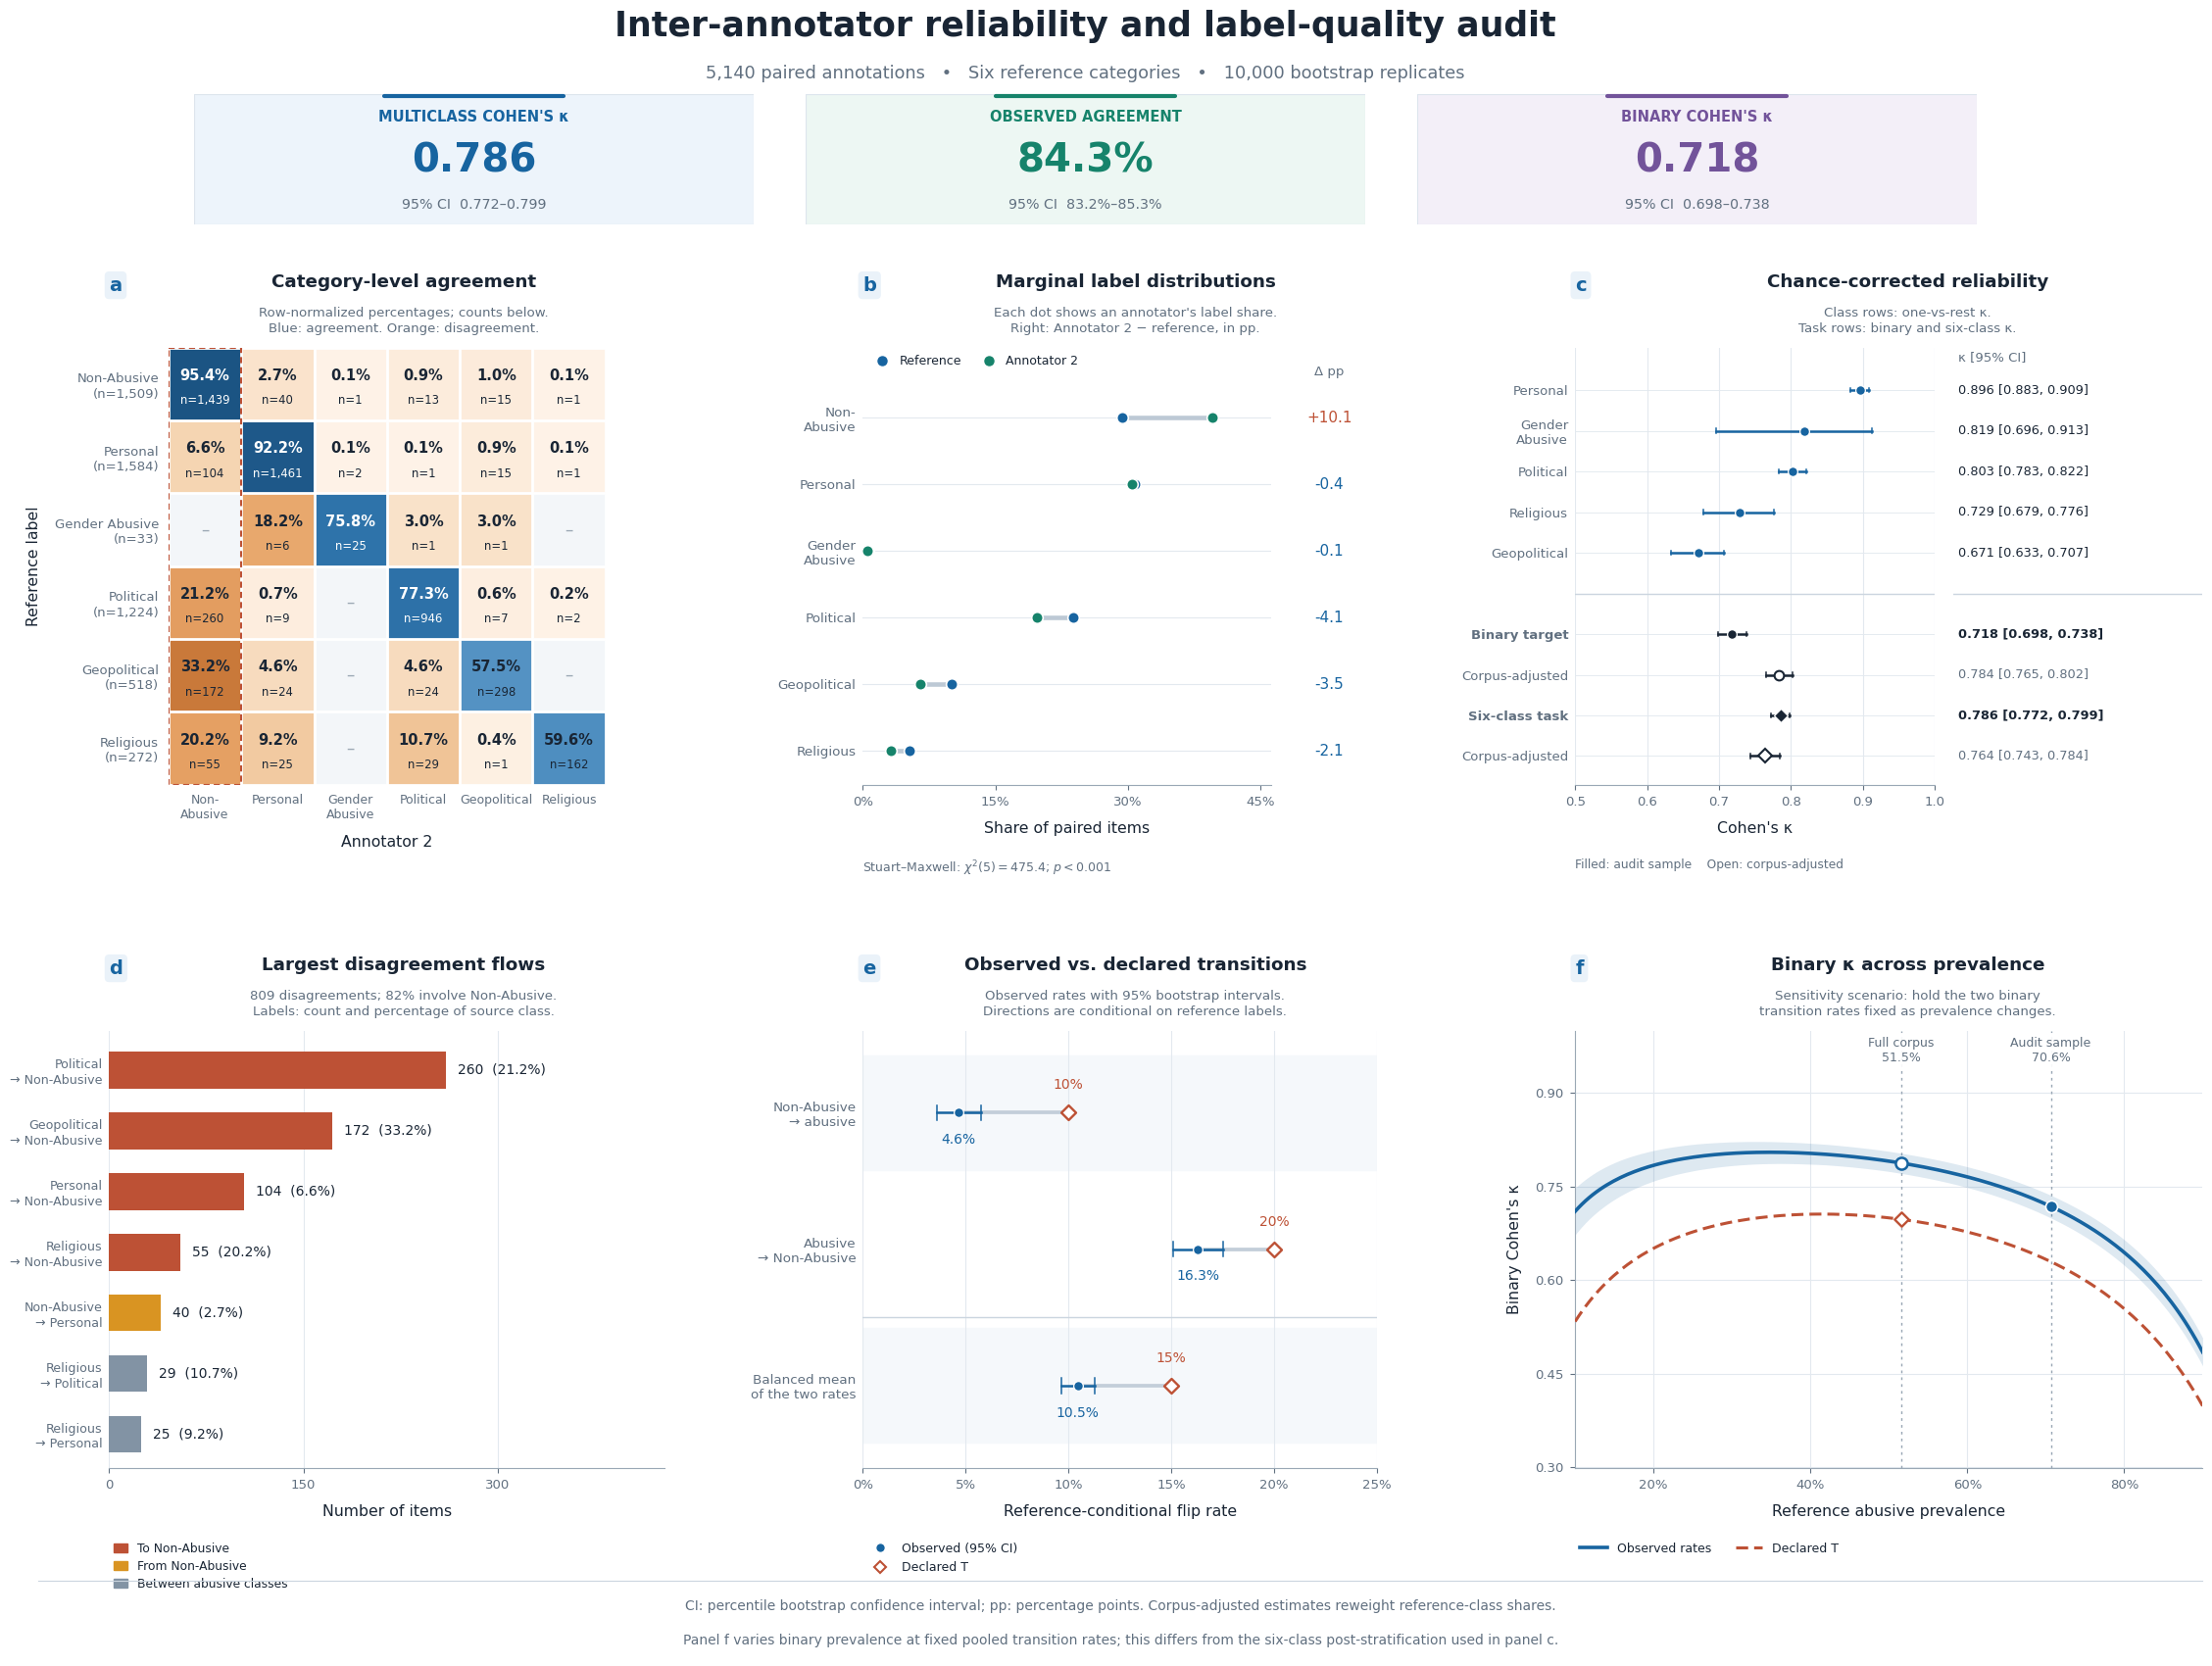

In [ ]:
import argparse
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MaxNLocator, PercentFormatter
from matplotlib.transforms import blended_transform_factory

from scipy.stats import chi2


logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)


# ============================================================================
# 1. CONFIGURATION
# ============================================================================

INPUT_FILE = "./Annotation.xlsx"
SHEET_NAME = "Sheet1"

REF_COL = "label"
ANN2_COL = "Jamil_lebel"

REF_NAME = "Reference label"
ANN2_NAME = "Annotator 2"

OUT_STEM = "fig1_inter_annotator_reliability"

N_BOOT = 10_000
SEED = 42

NON_ABUSIVE = "Non-Abusive"

T_DECLARED = {
    "na_to_ab": 0.10,
    "ab_to_na": 0.20,
}

CORPUS_COUNTS = {
    "Non-Abusive": 32938,
    "Religious": 9155,
    "Personal": 9057,
    "Political": 7006,
    "Geopolitical": 5746,
    "Gender Abusive": 4080,
}

DISPLAY_ORDER = [
    "Non-Abusive",
    "Personal",
    "Gender Abusive",
    "Political",
    "Geopolitical",
    "Religious",
]

C = {
    "blue": "#1764A0",
    "green": "#16836B",
    "orange": "#D99422",
    "red": "#BD5135",
    "purple": "#72539A",
    "ink": "#192534",
    "muted": "#617080",
    "grid": "#E3E9EF",
    "light": "#F5F8FB",
    "hair": "#CBD5DF",
    "gray": "#8293A4",
}

CMAP_AGREE = LinearSegmentedColormap.from_list(
    "agreement_blue",
    ["#F2F7FC", "#C8DDF0", "#7EAED4", "#347CB6", "#174D7A"],
)

CMAP_DISAGREE = LinearSegmentedColormap.from_list(
    "disagreement_orange",
    ["#FFF4EA", "#F5D3AE", "#E7A366", "#C67535"],
)

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "font.size": 10.5,
    "axes.labelsize": 11.3,
    "axes.titlesize": 13,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "axes.linewidth": 0.8,
    "axes.edgecolor": "#9AA8B5",
    "axes.labelcolor": C["ink"],
    "text.color": C["ink"],
    "xtick.color": C["muted"],
    "ytick.color": C["muted"],
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.facecolor": "white",
    "savefig.dpi": 450,
})


# ============================================================================
# 2. DATA LOADING
# ============================================================================

def load_pairs(path, sheet):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Input file not found: {path}")

    suffix = path.suffix.lower()

    if suffix == ".csv":
        df = pd.read_csv(path)
    elif suffix == ".tsv":
        df = pd.read_csv(path, sep="\t")
    else:
        df = pd.read_excel(path, sheet_name=sheet)

    missing = {REF_COL, ANN2_COL} - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    pairs = df[[REF_COL, ANN2_COL]].dropna().copy()

    canonical = {
        label.casefold(): label
        for label in DISPLAY_ORDER
    }

    for col in [REF_COL, ANN2_COL]:
        pairs[col] = (
            pairs[col]
            .astype(str)
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
            .str.replace("–", "-", regex=False)
            .str.replace("—", "-", regex=False)
        )

        pairs[col] = pairs[col].map(
            lambda value: canonical.get(
                value.casefold(), value
            )
        )

    pairs = pairs.loc[
        pairs[REF_COL].ne("")
        & pairs[ANN2_COL].ne("")
    ]

    if pairs.empty:
        raise ValueError(
            "No complete annotation pairs remain."
        )

    present = (
        set(pairs[REF_COL])
        | set(pairs[ANN2_COL])
    )

    unknown = present - set(DISPLAY_ORDER)

    if unknown:
        raise ValueError(
            "Unrecognized labels. Correct the following labels: "
            + ", ".join(sorted(unknown))
        )

    return (
        pairs[REF_COL].to_numpy(),
        pairs[ANN2_COL].to_numpy(),
    )


# ============================================================================
# 3. STATISTICS
# ============================================================================

def contingency(ref, ann, labels):
    k = len(labels)

    label_index = {
        label: i for i, label in enumerate(labels)
    }

    r = np.array(
        [label_index[value] for value in ref],
        dtype=int,
    )

    a = np.array(
        [label_index[value] for value in ann],
        dtype=int,
    )

    return np.bincount(
        r * k + a,
        minlength=k * k,
    ).reshape(k, k)


def safe_divide(a, b):
    a, b = np.broadcast_arrays(
        np.asarray(a, dtype=float),
        np.asarray(b, dtype=float),
    )

    out = np.full(
        a.shape,
        np.nan,
        dtype=float,
    )

    np.divide(
        a,
        b,
        out=out,
        where=np.abs(b) > 1e-14,
    )

    return out


def metrics(cm_batch, na_idx):
    cm = np.asarray(cm_batch, dtype=float)

    n = cm.sum(axis=(1, 2))
    diag = np.einsum("bii->bi", cm)

    row = cm.sum(axis=2)
    col = cm.sum(axis=1)

    po = safe_divide(
        diag.sum(axis=1),
        n,
    )

    pe = safe_divide(
        (row * col).sum(axis=1),
        n**2,
    )

    kappa = safe_divide(
        po - pe,
        1 - pe,
    )

    tp = diag
    fn = row - diag
    fp = col - diag
    tn = n[:, None] - tp - fn - fp

    po_binary = safe_divide(
        tp + tn,
        n[:, None],
    )

    pe_binary = safe_divide(
        (tp + fn) * (tp + fp)
        + (fp + tn) * (fn + tn),
        n[:, None]**2,
    )

    ovr = safe_divide(
        po_binary - pe_binary,
        1 - pe_binary,
    )

    na_to_ab = safe_divide(
        fn[:, na_idx],
        row[:, na_idx],
    )

    ab_to_na = safe_divide(
        fp[:, na_idx],
        n - row[:, na_idx],
    )

    return {
        "kappa": kappa,
        "agree": po,
        "ovr": ovr,
        "bin_agree": po_binary[:, na_idx],
        "flip_na_ab": na_to_ab,
        "flip_ab_na": ab_to_na,
        "flip_bal": 0.5 * (na_to_ab + ab_to_na),
    }


def post_stratify(cm_batch, corpus_share):
    cm = np.asarray(cm_batch, dtype=float)

    n = cm.sum(axis=(1, 2))

    reference_share = safe_divide(
        cm.sum(axis=2),
        n[:, None],
    )

    weights = safe_divide(
        corpus_share[None, :],
        reference_share,
    )

    return cm * weights[:, :, None]


def kappa_from_rates(pi, a, b):
    po = (
        (1 - pi) * (1 - a)
        + pi * (1 - b)
    )

    annotator_na_share = (
        (1 - pi) * (1 - a)
        + pi * b
    )

    pe = (
        (1 - pi) * annotator_na_share
        + pi * (1 - annotator_na_share)
    )

    return safe_divide(
        po - pe,
        1 - pe,
    )


def stuart_maxwell(cm):
    cm = np.asarray(cm, dtype=float)

    row = cm.sum(axis=1)
    col = cm.sum(axis=0)

    d = row - col

    covariance = -(cm + cm.T)

    np.fill_diagonal(
        covariance,
        row + col - 2 * np.diag(cm),
    )

    rank = int(
        np.linalg.matrix_rank(covariance)
    )

    if rank == 0:
        return 0.0, 0, 1.0

    statistic = max(
        0.0,
        float(
            d
            @ np.linalg.pinv(covariance)
            @ d
        ),
    )

    p_value = float(
        chi2.sf(statistic, rank)
    )

    return statistic, rank, p_value


def bootstrap(
    cm,
    na_idx,
    corpus_share,
    grid,
    n_boot,
    seed,
):
    if n_boot < 100:
        raise ValueError(
            "--n-boot must be at least 100."
        )

    rng = np.random.default_rng(seed)

    n = int(cm.sum())

    draws = rng.multinomial(
        n,
        cm.ravel() / n,
        size=n_boot,
    ).reshape(n_boot, *cm.shape)

    ordinary = metrics(draws, na_idx)

    valid_weighted = np.all(
        draws.sum(axis=2) > 0,
        axis=1,
    )

    n_valid = int(valid_weighted.sum())

    if n_valid < 100:
        raise ValueError(
            "Too few valid corpus-adjusted bootstrap replicates. "
            "Increase audit coverage for rare reference classes."
        )

    weighted = metrics(
        post_stratify(
            draws[valid_weighted],
            corpus_share,
        ),
        na_idx,
    )

    out = {
        key: np.nanpercentile(
            value,
            [2.5, 97.5],
            axis=0,
        )
        for key, value in ordinary.items()
    }

    out.update({
        f"{key}_w": np.nanpercentile(
            value,
            [2.5, 97.5],
            axis=0,
        )
        for key, value in weighted.items()
    })

    curves = kappa_from_rates(
        grid[None, :],
        ordinary["flip_na_ab"][:, None],
        ordinary["flip_ab_na"][:, None],
    )

    out["curve"] = np.nanpercentile(
        curves,
        [2.5, 97.5],
        axis=0,
    )

    out["n_weighted_valid"] = n_valid

    return out


# ============================================================================
# 4. VISUAL HELPERS
# ============================================================================

def short_label(label):
    return {
        "Non-Abusive": "Non-\nAbusive",
        "Gender Abusive": "Gender\nAbusive",
    }.get(label, label)


def clean_axis(ax, left=False):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if left:
        ax.spines["left"].set_visible(False)
        ax.tick_params(
            axis="y",
            length=0,
        )

    ax.tick_params(
        axis="both",
        which="major",
        pad=5,
    )


def make_panel(fig, slot, letter, title, subtitle):
    inner = slot.subgridspec(
        2, 1,
        height_ratios=[0.145, 0.855],
        hspace=0.025,
    )

    header = fig.add_subplot(inner[0])
    header.set_axis_off()

    header.text(
        0.0, 0.88,
        letter,
        transform=header.transAxes,
        ha="left",
        va="top",
        fontsize=14,
        fontweight="bold",
        color=C["blue"],
        bbox={
            "boxstyle": "round,pad=0.24",
            "facecolor": "#EAF2F9",
            "edgecolor": "none",
        },
    )

    header.text(
        0.53, 0.91,
        title,
        transform=header.transAxes,
        ha="center",
        va="top",
        fontsize=13.2,
        fontweight="bold",
        color=C["ink"],
    )

    header.text(
        0.53, 0.46,
        subtitle,
        transform=header.transAxes,
        ha="center",
        va="top",
        fontsize=9.6,
        color=C["muted"],
        linespacing=1.25,
    )

    return inner[1]


def draw_interval(
    ax,
    x,
    y,
    lo,
    hi,
    color,
    marker="o",
    hollow=False,
    cap_height=0.055,
):
    if np.isfinite(lo) and np.isfinite(hi):
        ax.plot(
            [lo, hi],
            [y, y],
            color=color,
            linewidth=1.8,
            zorder=3,
        )

        for end in [lo, hi]:
            ax.plot(
                [end, end],
                [y - cap_height, y + cap_height],
                color=color,
                linewidth=1.1,
                zorder=3,
            )

    if np.isfinite(x):
        ax.plot(
            x, y,
            marker=marker,
            markersize=7,
            linestyle="none",
            markerfacecolor="white" if hollow else color,
            markeredgecolor=color if hollow else "white",
            markeredgewidth=1.5 if hollow else 0.9,
            zorder=5,
        )


def p_label(p):
    if p < 0.001:
        return r"$p < 0.001$"

    return rf"$p = {p:.3f}$"


def add_stat_cards(fig, point, ci, na):
    cards = [
        {
            "label": "MULTICLASS COHEN'S κ",
            "value": f"{point['kappa']:.3f}",
            "detail": (
                "95% CI  "
                f"{ci['kappa'][0]:.3f}–"
                f"{ci['kappa'][1]:.3f}"
            ),
            "color": C["blue"],
            "background": "#EDF4FB",
        },
        {
            "label": "OBSERVED AGREEMENT",
            "value": f"{point['agree']:.1%}",
            "detail": (
                "95% CI  "
                f"{ci['agree'][0]:.1%}–"
                f"{ci['agree'][1]:.1%}"
            ),
            "color": C["green"],
            "background": "#EDF7F3",
        },
        {
            "label": "BINARY COHEN'S κ",
            "value": f"{point['ovr'][na]:.3f}",
            "detail": (
                "95% CI  "
                f"{ci['ovr'][0, na]:.3f}–"
                f"{ci['ovr'][1, na]:.3f}"
            ),
            "color": C["purple"],
            "background": "#F3EFF8",
        },
    ]

    card_width = 0.238
    card_gap = 0.022

    total_width = (
        3 * card_width
        + 2 * card_gap
    )

    group_left = (
        1 - total_width
    ) / 2

    for index, card in enumerate(cards):
        left = (
            group_left
            + index * (card_width + card_gap)
        )

        card_ax = fig.add_axes([
            left,
            0.850,
            card_width,
            0.076,
        ])

        card_ax.set_axis_off()

        card_ax.add_patch(
            Rectangle(
                (0, 0),
                1, 1,
                transform=card_ax.transAxes,
                facecolor=card["background"],
                edgecolor="#DDE5ED",
                linewidth=0.85,
                zorder=0,
            )
        )

        card_ax.plot(
            [0.34, 0.66],
            [0.985, 0.985],
            transform=card_ax.transAxes,
            color=card["color"],
            linewidth=3,
            solid_capstyle="round",
            clip_on=False,
        )

        card_ax.text(
            0.5, 0.82,
            card["label"],
            transform=card_ax.transAxes,
            ha="center",
            va="center",
            fontsize=10.5,
            fontweight="bold",
            color=card["color"],
        )

        card_ax.text(
            0.5, 0.48,
            card["value"],
            transform=card_ax.transAxes,
            ha="center",
            va="center",
            fontsize=29,
            fontweight="bold",
            color=card["color"],
        )

        card_ax.text(
            0.5, 0.15,
            card["detail"],
            transform=card_ax.transAxes,
            ha="center",
            va="center",
            fontsize=10.3,
            color=C["muted"],
        )


def add_footer(fig):
    footer_ax = fig.add_axes([
        0.055,
        0.015,
        0.920,
        0.045,
    ])

    footer_ax.set_axis_off()

    footer_ax.plot(
        [0, 1],
        [0.98, 0.98],
        transform=footer_ax.transAxes,
        color=C["hair"],
        linewidth=0.8,
        clip_on=False,
    )

    footer_ax.text(
        0.5, 0.65,
        (
            "CI: percentile bootstrap confidence interval; "
            "pp: percentage points. "
            "Corpus-adjusted estimates reweight reference-class shares."
        ),
        transform=footer_ax.transAxes,
        ha="center",
        va="center",
        fontsize=10,
        color=C["muted"],
    )

    footer_ax.text(
        0.5, 0.20,
        (
            "Panel f varies binary prevalence at fixed pooled transition "
            "rates; this differs from the six-class post-stratification "
            "used in panel c."
        ),
        transform=footer_ax.transAxes,
        ha="center",
        va="center",
        fontsize=10,
        color=C["muted"],
    )


# ============================================================================
# 5. MAIN ANALYSIS AND FIGURE
# ============================================================================

def main(args):
    ref, ann = load_pairs(
        args.input,
        args.sheet,
    )

    labels = DISPLAY_ORDER.copy()

    k = len(labels)
    na = labels.index(NON_ABUSIVE)

    cm = contingency(
        ref,
        ann,
        labels,
    )

    n = int(cm.sum())

    row_n = cm.sum(axis=1)
    col_n = cm.sum(axis=0)

    if np.any(row_n == 0):
        missing_classes = [
            labels[i]
            for i in np.flatnonzero(row_n == 0)
        ]

        raise ValueError(
            "Corpus adjustment requires audit examples for every "
            "reference class. Missing reference classes: "
            + ", ".join(missing_classes)
        )

    cm_norm = cm / row_n[:, None]

    corpus = np.array(
        [CORPUS_COUNTS[label] for label in labels],
        dtype=float,
    )

    corpus_share = corpus / corpus.sum()

    pi_sample = 1 - row_n[na] / n
    pi_corpus = 1 - corpus_share[na]

    grid_low = max(
        0.01,
        min(
            0.10,
            pi_sample - 0.05,
            pi_corpus - 0.05,
        ),
    )

    grid_high = min(
        0.99,
        max(
            0.90,
            pi_sample + 0.05,
            pi_corpus + 0.05,
        ),
    )

    grid = np.linspace(
        grid_low,
        grid_high,
        181,
    )

    point = {
        key: value[0]
        for key, value in metrics(
            cm[None], na
        ).items()
    }

    point_w = {
        key: value[0]
        for key, value in metrics(
            post_stratify(
                cm[None],
                corpus_share,
            ),
            na,
        ).items()
    }

    ci = bootstrap(
        cm,
        na,
        corpus_share,
        grid,
        args.n_boot,
        args.seed,
    )

    sm_stat, sm_df, sm_p = stuart_maxwell(cm)

    kappa = float(point["kappa"])
    binary_kappa = float(point["ovr"][na])

    curve_obs = kappa_from_rates(
        grid,
        point["flip_na_ab"],
        point["flip_ab_na"],
    )

    curve_t = kappa_from_rates(
        grid,
        T_DECLARED["na_to_ab"],
        T_DECLARED["ab_to_na"],
    )

    k_corpus_fixed = float(
        kappa_from_rates(
            pi_corpus,
            point["flip_na_ab"],
            point["flip_ab_na"],
        )
    )

    k_corpus_t = float(
        kappa_from_rates(
            pi_corpus,
            T_DECLARED["na_to_ab"],
            T_DECLARED["ab_to_na"],
        )
    )

    off = cm.copy()
    np.fill_diagonal(off, 0)

    n_disagree = int(off.sum())

    share_na = (
        (
            off[na].sum()
            + off[:, na].sum()
        ) / n_disagree
        if n_disagree else 0.0
    )

    flows = pd.DataFrame(
        [
            {
                "ref": labels[i],
                "ann": labels[j],
                "n": int(off[i, j]),
                "rate": off[i, j] / row_n[i],
            }
            for i in range(k)
            for j in range(k)
            if i != j and off[i, j] > 0
        ],
        columns=["ref", "ann", "n", "rate"],
    ).sort_values(
        "n",
        ascending=False,
    )

    # ========================================================================
    # FIGURE LAYOUT
    # ========================================================================

    fig = plt.figure(
        figsize=(24, 17.5),
        facecolor="white",
    )

    outer = fig.add_gridspec(
        2, 3,
        left=0.085,
        right=0.975,
        bottom=0.125,
        top=0.825 if not args.no_heading else 0.945,
        width_ratios=[1.08, 1.00, 1.22],
        wspace=0.35,
        hspace=0.32,
    )

    if not args.no_heading:
        fig.text(
            0.5, 0.975,
            "Inter-annotator reliability and label-quality audit",
            ha="center",
            va="top",
            fontsize=25,
            fontweight="bold",
            color=C["ink"],
        )

        fig.text(
            0.5, 0.943,
            (
                f"{n:,} paired annotations"
                "   •   Six reference categories"
                f"   •   {args.n_boot:,} bootstrap replicates"
            ),
            ha="center",
            va="top",
            fontsize=12.8,
            color=C["muted"],
        )

        add_stat_cards(
            fig,
            point,
            ci,
            na,
        )

    # ========================================================================
    # PANEL A: AGREEMENT MATRIX
    # ========================================================================

    slot_a = make_panel(
        fig,
        outer[0, 0],
        "a",
        "Category-level agreement",
        "Row-normalized percentages; counts below.\n"
        "Blue: agreement. Orange: disagreement.",
    )

    ax_a = fig.add_subplot(slot_a)

    rgba = np.zeros(
        (k, k, 4),
        dtype=float,
    )

    for i in range(k):
        for j in range(k):
            p = cm_norm[i, j]

            if i == j:
                rgba[i, j] = CMAP_AGREE(
                    0.15 + 0.85 * p
                )

            elif cm[i, j] == 0:
                rgba[i, j] = mpl.colors.to_rgba(
                    "#F3F6F9"
                )

            else:
                rgba[i, j] = CMAP_DISAGREE(
                    min(p / 0.35, 1.0)**0.7
                )

    ax_a.imshow(
        rgba,
        interpolation="nearest",
        aspect="equal",
    )

    ax_a.set_xticks(
        np.arange(-0.5, k, 1),
        minor=True,
    )

    ax_a.set_yticks(
        np.arange(-0.5, k, 1),
        minor=True,
    )

    ax_a.grid(
        which="minor",
        color="white",
        linewidth=2,
    )

    ax_a.tick_params(
        which="minor",
        length=0,
    )

    for i in range(k):
        for j in range(k):
            if cm[i, j] == 0:
                ax_a.text(
                    j, i,
                    "–",
                    ha="center",
                    va="center",
                    fontsize=12,
                    color="#9CA9B5",
                )
                continue

            rgb = rgba[i, j, :3]

            luminance = (
                0.2126 * rgb[0]
                + 0.7152 * rgb[1]
                + 0.0722 * rgb[2]
            )

            text_color = (
                "white"
                if luminance < 0.50
                else C["ink"]
            )

            ax_a.text(
                j, i - 0.11,
                f"{cm_norm[i, j]:.1%}",
                ha="center",
                va="center",
                fontsize=10.5,
                fontweight="bold",
                color=text_color,
            )

            ax_a.text(
                j, i + 0.23,
                f"n={cm[i, j]:,}",
                ha="center",
                va="center",
                fontsize=8.4,
                color=text_color,
            )

    ax_a.add_patch(
        Rectangle(
            (na - 0.5, -0.5),
            1, k,
            fill=False,
            edgecolor=C["red"],
            linewidth=1.5,
            linestyle=(0, (3, 2)),
            zorder=6,
        )
    )

    ax_a.set_xticks(range(k))

    ax_a.set_xticklabels(
        [short_label(label) for label in labels],
        fontsize=9,
        linespacing=1.15,
    )

    ax_a.set_yticks(range(k))

    ax_a.set_yticklabels(
        [
            f"{label}\n(n={row_n[i]:,})"
            for i, label in enumerate(labels)
        ],
        fontsize=9.5,
        linespacing=1.25,
    )

    ax_a.tick_params(
        axis="both",
        length=0,
        pad=7,
    )

    ax_a.set_xlabel(
        ANN2_NAME,
        labelpad=10,
    )

    ax_a.set_ylabel(
        REF_NAME,
        labelpad=10,
    )

    for spine in ax_a.spines.values():
        spine.set_visible(False)

    # ========================================================================
    # PANEL B: MARGINAL LABEL DISTRIBUTIONS
    # ========================================================================

    slot_b = make_panel(
        fig,
        outer[0, 1],
        "b",
        "Marginal label distributions",
        "Each dot shows an annotator's label share.\n"
        "Right: Annotator 2 − reference, in pp.",
    )

    sub_b = slot_b.subgridspec(
        1, 2,
        width_ratios=[0.81, 0.19],
        wspace=0.04,
    )

    ax_b = fig.add_subplot(sub_b[0])

    ax_b_delta = fig.add_subplot(
        sub_b[1],
        sharey=ax_b,
    )

    ref_share = row_n / n * 100
    ann_share = col_n / n * 100

    y_b = np.arange(k)

    for i in range(k):
        ax_b.axhline(
            i,
            color=C["grid"],
            linewidth=0.8,
            zorder=0,
        )

        ax_b.plot(
            [ref_share[i], ann_share[i]],
            [i, i],
            color="#BDC9D5",
            linewidth=3.3,
            solid_capstyle="round",
            zorder=2,
        )

        delta = ann_share[i] - ref_share[i]

        ax_b_delta.text(
            0.5, i,
            f"{delta:+.1f}",
            ha="center",
            va="center",
            fontsize=11,
            color=(
                C["red"]
                if delta > 0
                else C["blue"]
                if delta < 0
                else C["muted"]
            ),
        )

    ax_b.scatter(
        ref_share,
        y_b,
        s=70,
        color=C["blue"],
        edgecolor="white",
        linewidth=1.2,
        zorder=4,
    )

    ax_b.scatter(
        ann_share,
        y_b,
        s=70,
        color=C["green"],
        edgecolor="white",
        linewidth=1.2,
        zorder=5,
    )

    ax_b.set_yticks(y_b)

    ax_b.set_yticklabels(
        [short_label(label) for label in labels],
        fontsize=9.7,
    )

    # Extra top space accommodates the in-panel legend.
    ax_b.set_ylim(
        k - 0.5,
        -1.05,
    )

    share_max = max(
        ref_share.max(),
        ann_share.max(),
    )

    ax_b.set_xlim(
        0,
        min(
            105,
            max(20, share_max * 1.17),
        ),
    )

    ax_b.xaxis.set_major_locator(
        MaxNLocator(nbins=4)
    )

    ax_b.xaxis.set_major_formatter(
        PercentFormatter(
            xmax=100,
            decimals=0,
        )
    )

    ax_b.set_xlabel(
        "Share of paired items",
        labelpad=9,
    )

    clean_axis(
        ax_b,
        left=True,
    )

    ax_b_delta.set_xlim(0, 1)
    ax_b_delta.set_axis_off()

    ax_b_delta.text(
        0.5, -0.68,
        "Δ pp",
        ha="center",
        va="center",
        fontsize=9.5,
        color=C["muted"],
    )

    ax_b.legend(
        handles=[
            Line2D(
                [], [],
                marker="o",
                linestyle="none",
                color=C["blue"],
                label="Reference",
                markersize=6.5,
            ),
            Line2D(
                [], [],
                marker="o",
                linestyle="none",
                color=C["green"],
                label="Annotator 2",
                markersize=6.5,
            ),
        ],
        loc="upper left",
        ncol=2,
        frameon=False,
        fontsize=9,
        borderaxespad=0.2,
        handletextpad=0.4,
        columnspacing=1.2,
    )

    ax_b.text(
        0, -0.17,
        rf"Stuart–Maxwell: $\chi^2({sm_df})={sm_stat:.1f}$"
        + "; "
        + p_label(sm_p),
        transform=ax_b.transAxes,
        fontsize=9,
        color=C["muted"],
        ha="left",
        va="top",
    )

    # ========================================================================
    # PANEL C: RELIABILITY FOREST PLOT
    # ========================================================================

    slot_c = make_panel(
        fig,
        outer[0, 2],
        "c",
        "Chance-corrected reliability",
        "Class rows: one-vs-rest κ.\n"
        "Task rows: binary and six-class κ.",
    )

    sub_c = slot_c.subgridspec(
        1, 2,
        width_ratios=[0.59, 0.41],
        wspace=0.06,
    )

    ax_c = fig.add_subplot(sub_c[0])

    ax_c_ci = fig.add_subplot(
        sub_c[1],
        sharey=ax_c,
    )

    class_indices = [
        i
        for i in np.argsort(-point["ovr"])
        if i != na
    ]

    forest_rows = []

    for rank, idx in enumerate(class_indices):
        forest_rows.append({
            "y": 9 - rank,
            "label": short_label(labels[idx]),
            "value": float(point["ovr"][idx]),
            "lo": float(ci["ovr"][0, idx]),
            "hi": float(ci["ovr"][1, idx]),
            "color": C["blue"],
            "marker": "o",
            "hollow": False,
        })

    forest_rows.extend([
        {
            "y": 3,
            "label": "Binary target",
            "value": binary_kappa,
            "lo": float(ci["ovr"][0, na]),
            "hi": float(ci["ovr"][1, na]),
            "color": C["ink"],
            "marker": "o",
            "hollow": False,
        },
        {
            "y": 2,
            "label": "Corpus-adjusted",
            "value": float(point_w["ovr"][na]),
            "lo": float(ci["ovr_w"][0, na]),
            "hi": float(ci["ovr_w"][1, na]),
            "color": C["ink"],
            "marker": "o",
            "hollow": True,
        },
        {
            "y": 1,
            "label": "Six-class task",
            "value": kappa,
            "lo": float(ci["kappa"][0]),
            "hi": float(ci["kappa"][1]),
            "color": C["ink"],
            "marker": "D",
            "hollow": False,
        },
        {
            "y": 0,
            "label": "Corpus-adjusted",
            "value": float(point_w["kappa"]),
            "lo": float(ci["kappa_w"][0]),
            "hi": float(ci["kappa_w"][1]),
            "color": C["ink"],
            "marker": "D",
            "hollow": True,
        },
    ])

    finite_limits = np.array([
        value
        for row in forest_rows
        for value in [
            row["value"],
            row["lo"],
            row["hi"],
        ]
        if np.isfinite(value)
    ])

    if finite_limits.size:
        x_low = max(
            -1,
            np.floor(
                (finite_limits.min() - 0.04) * 10
            ) / 10,
        )

        x_high = min(
            1,
            np.ceil(
                (finite_limits.max() + 0.04) * 10
            ) / 10,
        )
    else:
        x_low, x_high = -1, 1

    if x_high - x_low < 0.25:
        x_low = max(
            -1,
            x_high - 0.25,
        )

    for row in forest_rows:
        ax_c.axhline(
            row["y"],
            color=C["grid"],
            linewidth=0.65,
            zorder=0,
        )

        draw_interval(
            ax_c,
            row["value"],
            row["y"],
            row["lo"],
            row["hi"],
            row["color"],
            marker=row["marker"],
            hollow=row["hollow"],
        )

        if all(
            np.isfinite(row[key])
            for key in ["value", "lo", "hi"]
        ):
            value_text = (
                f"{row['value']:.3f} "
                f"[{row['lo']:.3f}, {row['hi']:.3f}]"
            )
        else:
            value_text = "Not estimable"

        ax_c_ci.text(
            0.02,
            row["y"],
            value_text,
            ha="left",
            va="center",
            fontsize=9.3,
            color=(
                C["muted"]
                if row["hollow"]
                else C["ink"]
            ),
            fontweight=(
                "bold"
                if row["y"] in (3, 1)
                else "normal"
            ),
        )

    for axis in [ax_c, ax_c_ci]:
        axis.axhline(
            4,
            color=C["hair"],
            linewidth=1,
        )

        axis.set_ylim(
            -0.7,
            10.05,
        )

    ax_c.set_xlim(
        x_low,
        x_high,
    )

    ax_c.xaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax_c.set_yticks(
        [row["y"] for row in forest_rows]
    )

    ax_c.set_yticklabels(
        [row["label"] for row in forest_rows],
        fontsize=9.5,
    )

    for tick, row in zip(
        ax_c.get_yticklabels(),
        forest_rows,
    ):
        if row["y"] in (3, 1):
            tick.set_fontweight("bold")

        if row["hollow"]:
            tick.set_color(C["muted"])

    ax_c.grid(
        axis="x",
        color=C["grid"],
        linewidth=0.8,
    )

    ax_c.set_axisbelow(True)

    ax_c.set_xlabel(
        "Cohen's κ",
        labelpad=9,
    )

    clean_axis(
        ax_c,
        left=True,
    )

    ax_c_ci.set_xlim(0, 1)
    ax_c_ci.set_axis_off()

    ax_c_ci.text(
        0.02, 9.82,
        "κ [95% CI]",
        ha="left",
        va="center",
        fontsize=9.5,
        color=C["muted"],
    )

    ax_c.text(
        0, -0.17,
        "Filled: audit sample    Open: corpus-adjusted",
        transform=ax_c.transAxes,
        fontsize=8.8,
        color=C["muted"],
        ha="left",
        va="top",
    )

    # ========================================================================
    # PANEL D: DISAGREEMENT FLOWS
    # ========================================================================

    slot_d = make_panel(
        fig,
        outer[1, 0],
        "d",
        "Largest disagreement flows",
        (
            f"{n_disagree:,} disagreements; "
            f"{share_na:.0%} involve Non-Abusive.\n"
            "Labels: count and percentage of source class."
        ),
    )

    ax_d = fig.add_subplot(slot_d)

    top = flows.head(7).reset_index(drop=True)

    if top.empty:
        ax_d.text(
            0.5, 0.5,
            "No observed disagreements",
            transform=ax_d.transAxes,
            ha="center",
            va="center",
            fontsize=13,
            color=C["muted"],
        )

        ax_d.set_axis_off()

    else:
        y_d = np.arange(len(top))

        def flow_color(row):
            if row.ann == NON_ABUSIVE:
                return C["red"]

            if row.ref == NON_ABUSIVE:
                return C["orange"]

            return C["gray"]

        ax_d.barh(
            y_d,
            top["n"],
            color=[
                flow_color(row)
                for row in top.itertuples()
            ],
            height=0.61,
            zorder=3,
        )

        max_n = float(top["n"].max())

        for y, row in zip(
            y_d,
            top.itertuples(),
        ):
            ax_d.text(
                row.n + max_n * 0.035,
                y,
                f"{row.n:,}  ({row.rate:.1%})",
                ha="left",
                va="center",
                fontsize=10,
            )

        ax_d.set_yticks(y_d)

        ax_d.set_yticklabels(
            [
                f"{row.ref}\n→ {row.ann}"
                for row in top.itertuples()
            ],
            fontsize=9.1,
            linespacing=1.25,
        )

        ax_d.set_ylim(
            len(top) - 0.45,
            -0.65,
        )

        ax_d.set_xlim(
            0,
            max_n * 1.65,
        )

        ax_d.xaxis.set_major_locator(
            MaxNLocator(
                nbins=4,
                integer=True,
            )
        )

        ax_d.grid(
            axis="x",
            color=C["grid"],
            linewidth=0.8,
        )

        ax_d.set_axisbelow(True)

        ax_d.set_xlabel(
            "Number of items",
            labelpad=9,
        )

        clean_axis(
            ax_d,
            left=True,
        )

        ax_d.legend(
            handles=[
                Patch(
                    color=C["red"],
                    label="To Non-Abusive",
                ),
                Patch(
                    color=C["orange"],
                    label="From Non-Abusive",
                ),
                Patch(
                    color=C["gray"],
                    label="Between abusive classes",
                ),
            ],
            loc="upper left",
            bbox_to_anchor=(0, -0.16),
            ncol=1,
            frameon=False,
            fontsize=8.8,
            borderaxespad=0,
            handlelength=1.1,
            labelspacing=0.4,
        )

    # ========================================================================
    # PANEL E: OBSERVED VS DECLARED TRANSITIONS
    # ========================================================================

    slot_e = make_panel(
        fig,
        outer[1, 1],
        "e",
        "Observed vs. declared transitions",
        "Observed rates with 95% bootstrap intervals.\n"
        "Directions are conditional on reference labels.",
    )

    ax_e = fig.add_subplot(slot_e)

    transition_rows = [
        (
            "Non-Abusive\n→ abusive",
            "flip_na_ab",
            T_DECLARED["na_to_ab"],
        ),
        (
            "Abusive\n→ Non-Abusive",
            "flip_ab_na",
            T_DECLARED["ab_to_na"],
        ),
        (
            "Balanced mean\nof the two rates",
            "flip_bal",
            np.mean(
                list(T_DECLARED.values())
            ),
        ),
    ]

    transition_max = max(
        max(
            float(ci[key][1])
            for _, key, _ in transition_rows
        ),
        max(
            target
            for _, _, target in transition_rows
        ),
    ) * 100

    limit_e = min(
        105,
        max(
            25,
            np.ceil(
                (transition_max + 4) / 5
            ) * 5,
        ),
    )

    for y, (_, key, declared) in zip(
        [2, 1, 0],
        transition_rows,
    ):
        observed = float(point[key]) * 100

        lo, hi = (
            np.asarray(ci[key], dtype=float)
            * 100
        )

        target = declared * 100

        ax_e.axhspan(
            y - 0.42,
            y + 0.42,
            color=(
                C["light"]
                if y != 1
                else "white"
            ),
            zorder=0,
        )

        ax_e.plot(
            [observed, target],
            [y, y],
            color="#C3CED9",
            linewidth=2.7,
            zorder=2,
        )

        draw_interval(
            ax_e,
            observed,
            y,
            lo,
            hi,
            C["blue"],
        )

        ax_e.scatter(
            target,
            y,
            marker="D",
            s=58,
            facecolors="white",
            edgecolors=C["red"],
            linewidths=1.7,
            zorder=6,
        )

        ax_e.annotate(
            f"{observed:.1f}%",
            xy=(observed, y),
            xytext=(0, -15),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=10,
            color=C["blue"],
        )

        ax_e.annotate(
            f"{target:.0f}%",
            xy=(target, y),
            xytext=(0, 15),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            color=C["red"],
        )

    ax_e.axhline(
        0.5,
        color=C["hair"],
        linewidth=1,
    )

    ax_e.set_yticks([2, 1, 0])

    ax_e.set_yticklabels(
        [row[0] for row in transition_rows],
        fontsize=9.7,
    )

    ax_e.set_ylim(
        -0.6,
        2.6,
    )

    ax_e.set_xlim(
        0,
        limit_e,
    )

    ax_e.xaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax_e.xaxis.set_major_formatter(
        PercentFormatter(
            xmax=100,
            decimals=0,
        )
    )

    ax_e.grid(
        axis="x",
        color=C["grid"],
        linewidth=0.8,
    )

    ax_e.set_axisbelow(True)

    ax_e.set_xlabel(
        "Reference-conditional flip rate",
        labelpad=9,
    )

    clean_axis(
        ax_e,
        left=True,
    )

    ax_e.legend(
        handles=[
            Line2D(
                [], [],
                marker="o",
                linestyle="none",
                markerfacecolor=C["blue"],
                markeredgecolor="white",
                markersize=7,
                label="Observed (95% CI)",
            ),
            Line2D(
                [], [],
                marker="D",
                linestyle="none",
                markerfacecolor="white",
                markeredgecolor=C["red"],
                markeredgewidth=1.5,
                markersize=6.5,
                label="Declared T",
            ),
        ],
        loc="upper left",
        bbox_to_anchor=(0, -0.16),
        frameon=False,
        fontsize=9,
        ncol=1,
        borderaxespad=0,
    )

    # ========================================================================
    # PANEL F: PREVALENCE SENSITIVITY
    # ========================================================================

    slot_f = make_panel(
        fig,
        outer[1, 2],
        "f",
        "Binary κ across prevalence",
        "Sensitivity scenario: hold the two binary\n"
        "transition rates fixed as prevalence changes.",
    )

    ax_f = fig.add_subplot(slot_f)

    ax_f.fill_between(
        grid,
        ci["curve"][0],
        ci["curve"][1],
        color=C["blue"],
        alpha=0.14,
        linewidth=0,
        zorder=2,
    )

    ax_f.plot(
        grid,
        curve_obs,
        color=C["blue"],
        linewidth=2.6,
        label="Observed rates",
        zorder=4,
    )

    ax_f.plot(
        grid,
        curve_t,
        color=C["red"],
        linewidth=2.2,
        linestyle=(0, (4, 2)),
        label="Declared T",
        zorder=3,
    )

    for prevalence in [
        pi_sample,
        pi_corpus,
    ]:
        ax_f.axvline(
            prevalence,
            color="#98A6B4",
            linewidth=1,
            linestyle=(0, (2, 3)),
            zorder=1,
        )

    ax_f.scatter(
        pi_sample,
        binary_kappa,
        s=76,
        color=C["blue"],
        edgecolors="white",
        linewidths=1.2,
        zorder=6,
    )

    ax_f.scatter(
        pi_corpus,
        k_corpus_fixed,
        s=76,
        facecolors="white",
        edgecolors=C["blue"],
        linewidths=1.8,
        zorder=6,
    )

    ax_f.scatter(
        pi_corpus,
        k_corpus_t,
        marker="D",
        s=54,
        facecolors="white",
        edgecolors=C["red"],
        linewidths=1.7,
        zorder=6,
    )

    all_y = np.concatenate([
        ci["curve"].ravel(),
        np.asarray(curve_t).ravel(),
        [
            binary_kappa,
            k_corpus_fixed,
            k_corpus_t,
        ],
    ])

    all_y = all_y[
        np.isfinite(all_y)
    ]

    y_min = max(
        -1,
        np.floor(
            (all_y.min() - 0.04) * 10
        ) / 10,
    )

    y_max = min(
        1,
        np.ceil(
            (all_y.max() + 0.09) * 10
        ) / 10,
    )

    ax_f.set_ylim(
        y_min,
        y_max,
    )

    ax_f.set_xlim(
        grid[0],
        grid[-1],
    )

    marker_transform = blended_transform_factory(
        ax_f.transData,
        ax_f.transAxes,
    )

    close_markers = (
        abs(pi_sample - pi_corpus) < 0.12
    )

    if close_markers:
        if pi_sample <= pi_corpus:
            sample_offset = -5
            sample_ha = "right"
            corpus_offset = 5
            corpus_ha = "left"
        else:
            sample_offset = 5
            sample_ha = "left"
            corpus_offset = -5
            corpus_ha = "right"
    else:
        sample_offset = 0
        corpus_offset = 0
        sample_ha = "center"
        corpus_ha = "center"

    ax_f.annotate(
        f"Audit sample\n{pi_sample:.1%}",
        xy=(pi_sample, 0.985),
        xycoords=marker_transform,
        xytext=(sample_offset, 0),
        textcoords="offset points",
        ha=sample_ha,
        va="top",
        fontsize=9,
        color=C["muted"],
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.92,
            "pad": 2,
        },
    )

    ax_f.annotate(
        f"Full corpus\n{pi_corpus:.1%}",
        xy=(pi_corpus, 0.985),
        xycoords=marker_transform,
        xytext=(corpus_offset, 0),
        textcoords="offset points",
        ha=corpus_ha,
        va="top",
        fontsize=9,
        color=C["muted"],
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.92,
            "pad": 2,
        },
    )

    ax_f.xaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax_f.xaxis.set_major_formatter(
        PercentFormatter(
            xmax=1,
            decimals=0,
        )
    )

    ax_f.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax_f.set_xlabel(
        "Reference abusive prevalence",
        labelpad=9,
    )

    ax_f.set_ylabel(
        "Binary Cohen's κ",
        labelpad=9,
    )

    ax_f.grid(
        color=C["grid"],
        linewidth=0.8,
    )

    ax_f.set_axisbelow(True)

    clean_axis(ax_f)

    ax_f.legend(
        loc="upper left",
        bbox_to_anchor=(0, -0.16),
        ncol=2,
        frameon=False,
        fontsize=9,
        borderaxespad=0,
        handlelength=2.2,
    )

    # ========================================================================
    # DEDICATED FOOTER
    # ========================================================================

    add_footer(fig)

    # ========================================================================
    # EXPORT
    # ========================================================================

    stem = Path(args.out)

    stem.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    for extension in [
        "pdf",
        "svg",
        "png",
    ]:
        options = (
            {"dpi": args.dpi}
            if extension == "png"
            else {}
        )

        fig.savefig(
            str(stem) + f".{extension}",
            bbox_inches="tight",
            pad_inches=0.16,
            facecolor="white",
            **options,
        )

    summary_rows = []

    for key in [
        "kappa",
        "agree",
        "bin_agree",
        "flip_na_ab",
        "flip_ab_na",
        "flip_bal",
    ]:
        summary_rows.append({
            "metric": key,
            "estimate": float(point[key]),
            "ci_low": float(ci[key][0]),
            "ci_high": float(ci[key][1]),
        })

    for i, label in enumerate(labels):
        summary_rows.append({
            "metric": f"ovr_kappa_{label}",
            "estimate": float(
                point["ovr"][i]
            ),
            "ci_low": float(
                ci["ovr"][0, i]
            ),
            "ci_high": float(
                ci["ovr"][1, i]
            ),
        })

    for key in [
        "kappa",
        "bin_agree",
    ]:
        summary_rows.append({
            "metric": f"corpus_adjusted_{key}",
            "estimate": float(
                point_w[key]
            ),
            "ci_low": float(
                ci[f"{key}_w"][0]
            ),
            "ci_high": float(
                ci[f"{key}_w"][1]
            ),
        })

    summary_rows.append({
        "metric": "corpus_adjusted_binary_kappa",
        "estimate": float(
            point_w["ovr"][na]
        ),
        "ci_low": float(
            ci["ovr_w"][0, na]
        ),
        "ci_high": float(
            ci["ovr_w"][1, na]
        ),
    })

    pd.DataFrame(
        summary_rows
    ).to_csv(
        str(stem) + "_summary.csv",
        index=False,
    )

    pd.DataFrame(
        cm,
        index=labels,
        columns=labels,
    ).rename_axis(
        index=REF_NAME,
        columns=ANN2_NAME,
    ).to_csv(
        str(stem) + "_confusion_matrix.csv"
    )

    print(
        f"Paired annotations: {n:,}"
    )

    print(
        f"Multiclass kappa: {kappa:.4f} "
        f"[{ci['kappa'][0]:.4f}, "
        f"{ci['kappa'][1]:.4f}]"
    )

    print(
        f"Observed agreement: {point['agree']:.2%}"
    )

    print(
        f"Binary kappa: {binary_kappa:.4f} "
        f"[{ci['ovr'][0, na]:.4f}, "
        f"{ci['ovr'][1, na]:.4f}]"
    )

    print(
        "Valid corpus-adjusted bootstrap replicates: "
        f"{ci['n_weighted_valid']:,}"
        f"/{args.n_boot:,}"
    )

    if ci["n_weighted_valid"] < args.n_boot:
        print(
            "Note: corpus-adjusted intervals exclude bootstrap "
            "replicates with an absent reference class."
        )

    print(
        f"Saved figure outputs and numerical tables: {stem}"
    )

    return fig


# ============================================================================
# 6. COMMAND-LINE ENTRY POINT
# ============================================================================

if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description=(
            "Create a six-panel inter-annotator "
            "reliability and label-quality figure."
        )
    )

    parser.add_argument(
        "--input",
        default=INPUT_FILE,
        help="Excel, CSV, or TSV annotation file.",
    )

    parser.add_argument(
        "--sheet",
        default=SHEET_NAME,
        help="Excel worksheet name.",
    )

    parser.add_argument(
        "--out",
        default=OUT_STEM,
        help="Output filename stem.",
    )

    parser.add_argument(
        "--n-boot",
        type=int,
        default=N_BOOT,
        help="Number of bootstrap replicates.",
    )

    parser.add_argument(
        "--seed",
        type=int,
        default=SEED,
        help="Random seed.",
    )

    parser.add_argument(
        "--dpi",
        type=int,
        default=450,
        help="PNG export resolution.",
    )

    parser.add_argument(
        "--no-heading",
        action="store_true",
        help=(
            "Remove the global title, subtitle, "
            "and statistic cards."
        ),
    )

    args, _ = parser.parse_known_args()

    figure = main(args)

    plt.show()

kappa=0.7858 (np.float64(0.7721739525987192), np.float64(0.798947194966911)) | binary=0.7184 (np.float64(0.6981858250681224), np.float64(0.73779927418084)) | agree=0.8426 | SM chi2(5)=475.4


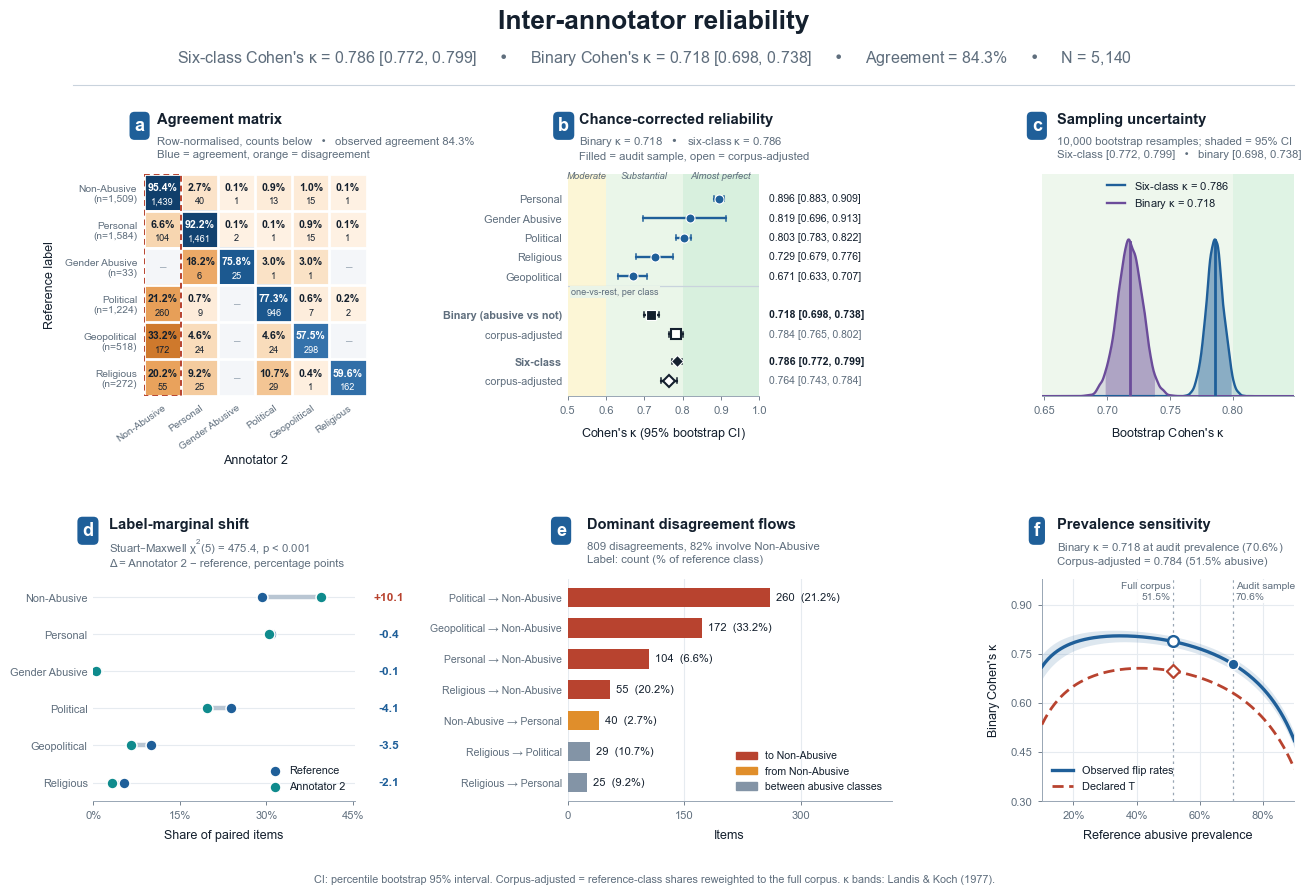

In [13]:

import argparse, logging
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy.stats import chi2, gaussian_kde
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# ------------------------------------------------------------------ config
INPUT_FILE, SHEET = "./Annotation.xlsx", "Sheet1"
REF_COL, ANN_COL = "label", "Jamil_lebel"
REF_NAME, ANN_NAME = "Reference label", "Annotator 2"
OUT_STEM, N_BOOT, SEED = "fig_reliability", 10_000, 42
NA = "Non-Abusive"
T_DECLARED = {"na_to_ab": 0.10, "ab_to_na": 0.20}
CORPUS = {"Non-Abusive": 32938, "Religious": 9155, "Personal": 9057,
          "Political": 7006, "Geopolitical": 5746, "Gender Abusive": 4080}
ORDER = ["Non-Abusive", "Personal", "Gender Abusive", "Political", "Geopolitical", "Religious"]
DEMO_CM = pd.DataFrame(  # rows = reference, cols = annotator 2 (published counts)
    [[1439, 40, 1, 13, 15, 1], [104, 1461, 2, 1, 15, 1], [0, 6, 25, 1, 1, 0],
     [260, 9, 0, 946, 7, 2], [172, 24, 0, 24, 298, 0], [55, 25, 0, 29, 1, 162]],
    index=ORDER, columns=ORDER)

C = dict(blue="#1F5F99", teal="#0F8B8D", orange="#E08E2B", red="#B8432F", ink="#14202E",
         muted="#5F6E7D", grid="#E6EBF0", hair="#C9D3DD", gray="#8394A6", purple="#6B4C9A")
BANDS = [(0.0, 0.2, "#FBE4E1", "Slight"), (0.2, 0.4, "#FCEBD6", "Fair"), (0.4, 0.6, "#FBF3C9", "Moderate"),
         (0.6, 0.8, "#E3F3E2", "Substantial"), (0.8, 1.0, "#CBEBD3", "Almost perfect")]
CM_AGREE = LinearSegmentedColormap.from_list("a", ["#EAF2FA", "#9CC3E4", "#4A86BE", "#1F5F99", "#0E3A63"])
CM_DIS = LinearSegmentedColormap.from_list("d", ["#FFF3E6", "#F7D4AC", "#EBA55F", "#CC7427"])

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.7, "axes.edgecolor": "#98A6B4", "axes.labelcolor": C["ink"],
    "text.color": C["ink"], "xtick.color": C["muted"], "ytick.color": C["muted"],
    "axes.spines.top": False, "axes.spines.right": False, "mathtext.default": "regular",
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "savefig.facecolor": "white"})

# ------------------------------------------------------------------ data
def load_pairs(path, sheet):
    p = Path(path); suf = p.suffix.lower()
    df = (pd.read_csv(p) if suf == ".csv" else pd.read_csv(p, sep="\t") if suf == ".tsv"
          else pd.read_excel(p, sheet_name=sheet))
    d = df[[REF_COL, ANN_COL]].dropna().astype(str)
    canon = {l.casefold(): l for l in ORDER}
    for c in d:
        d[c] = d[c].str.strip().str.replace(r"\s+", " ", regex=True).str.replace("[–—]", "-", regex=True)
        d[c] = d[c].map(lambda v: canon.get(v.casefold(), v))
    bad = (set(d[REF_COL]) | set(d[ANN_COL])) - set(ORDER)
    if bad: raise ValueError(f"Unrecognised labels: {sorted(bad)}")
    return d[REF_COL].to_numpy(), d[ANN_COL].to_numpy()

def contingency(ref, ann, labels):
    k = len(labels); ix = {l: i for i, l in enumerate(labels)}
    r = np.array([ix[v] for v in ref]); a = np.array([ix[v] for v in ann])
    return np.bincount(r * k + a, minlength=k * k).reshape(k, k)

# ------------------------------------------------------------------ statistics
def sdiv(a, b):
    a, b = np.broadcast_arrays(np.asarray(a, float), np.asarray(b, float))
    out = np.full(a.shape, np.nan); np.divide(a, b, out=out, where=np.abs(b) > 1e-14); return out

def metrics(cmb, na):
    cm = np.asarray(cmb, float); n = cm.sum((1, 2)); diag = np.einsum("bii->bi", cm)
    row, col = cm.sum(2), cm.sum(1)
    po = sdiv(diag.sum(1), n); pe = sdiv((row * col).sum(1), n ** 2)
    tp, fn, fp = diag, row - diag, col - diag; tn = n[:, None] - tp - fn - fp
    pob = sdiv(tp + tn, n[:, None])
    peb = sdiv((tp + fn) * (tp + fp) + (fp + tn) * (fn + tn), n[:, None] ** 2)
    f1, f2 = sdiv(fn[:, na], row[:, na]), sdiv(fp[:, na], n - row[:, na])
    return dict(kappa=sdiv(po - pe, 1 - pe), agree=po, ovr=sdiv(pob - peb, 1 - peb),
                na_ab=f1, ab_na=f2, bal=.5 * (f1 + f2))

def post_strat(cmb, share):
    cm = np.asarray(cmb, float); n = cm.sum((1, 2))
    return cm * sdiv(share[None, :], sdiv(cm.sum(2), n[:, None]))[:, :, None]

def kappa_rates(pi, a, b):
    po = (1 - pi) * (1 - a) + pi * (1 - b); q = (1 - pi) * (1 - a) + pi * b
    return sdiv(po - ((1 - pi) * q + pi * (1 - q)), 1 - ((1 - pi) * q + pi * (1 - q)))

def stuart_maxwell(cm):
    cm = np.asarray(cm, float); r, c = cm.sum(1), cm.sum(0); d = r - c
    cov = -(cm + cm.T); np.fill_diagonal(cov, r + c - 2 * np.diag(cm))
    rk = int(np.linalg.matrix_rank(cov)); s = max(0., float(d @ np.linalg.pinv(cov) @ d))
    return s, rk, float(chi2.sf(s, rk))

def bootstrap(cm, na, share, grid, nb, seed):
    rng = np.random.default_rng(seed); n = int(cm.sum())
    dr = rng.multinomial(n, cm.ravel() / n, size=nb).reshape(nb, *cm.shape)
    m = metrics(dr, na); ok = np.all(dr.sum(2) > 0, 1); mw = metrics(post_strat(dr[ok], share), na)
    ci = {k: np.nanpercentile(v, [2.5, 97.5], 0) for k, v in m.items()}
    ci.update({k + "_w": np.nanpercentile(v, [2.5, 97.5], 0) for k, v in mw.items()})
    ci["curve"] = np.nanpercentile(kappa_rates(grid[None], m["na_ab"][:, None], m["ab_na"][:, None]), [2.5, 97.5], 0)
    return ci, m

# ------------------------------------------------------------------ helpers
def flat(l): return l.replace("\n", "")
def short(l): return {"Non-Abusive": "Non-\nAbusive", "Gender Abusive": "Gender\nAbusive"}.get(l, l)

def letter(ax, s):
    ax.text(-0.02, 1.215, s, transform=ax.transAxes, fontsize=13, fontweight="bold", color="white", ha="center",
            va="center", bbox=dict(boxstyle="round,pad=0.28", fc=C["blue"], ec="none"))

def heading(ax, title, sub, dx=0.06):
    ax.text(dx, 1.245, title, transform=ax.transAxes, fontsize=10.5, fontweight="bold", va="center", ha="left")
    ax.text(dx, 1.115, sub, transform=ax.transAxes, fontsize=8.2, color=C["muted"], va="center", ha="left",
            linespacing=1.3)

def interval(ax, x, y, lo, hi, color, marker="o", hollow=False, ms=6.5):
    ax.plot([lo, hi], [y, y], color=color, lw=1.7, zorder=3, solid_capstyle="round")
    for e in (lo, hi): ax.plot([e, e], [y - .13, y + .13], color=color, lw=1.1, zorder=3)
    ax.plot(x, y, marker=marker, ms=ms, ls="none", mfc="white" if hollow else color,
            mec=color if hollow else "white", mew=1.5 if hollow else .8, zorder=5)

def tidy(ax, left=False):
    if left: ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    ax.tick_params(pad=4)

def pct_axis(ax, xmax=100, which="x"):
    getattr(ax, f"{which}axis").set_major_formatter(PercentFormatter(xmax=xmax, decimals=0))

# ------------------------------------------------------------------ main
def main(a):
    if a.demo:
        cm = DEMO_CM.to_numpy().astype(int); print("[demo] using published confusion matrix")
    else:
        ref, ann = load_pairs(a.input, a.sheet); cm = contingency(ref, ann, ORDER)
    labels, k = ORDER, len(ORDER); na = labels.index(NA)
    n = int(cm.sum()); rn, cn = cm.sum(1), cm.sum(0); cmn = cm / rn[:, None]
    corpus = np.array([CORPUS[l] for l in labels], float); share = corpus / corpus.sum()
    pi_s, pi_c = 1 - rn[na] / n, 1 - share[na]
    grid = np.linspace(.10, .90, 161)
    P = {x: v[0] for x, v in metrics(cm[None], na).items()}
    PW = {x: v[0] for x, v in metrics(post_strat(cm[None], share), na).items()}
    ci, boot = bootstrap(cm, na, share, grid, a.n_boot, a.seed)
    sm, df, sp = stuart_maxwell(cm)
    kap, bkap = float(P["kappa"]), float(P["ovr"][na])
    off = cm.copy(); np.fill_diagonal(off, 0); nd = int(off.sum())
    share_na = (off[na].sum() + off[:, na].sum()) / nd
    flows = pd.DataFrame([dict(r=labels[i], c=labels[j], n=int(off[i, j]), rate=off[i, j] / rn[i])
                          for i in range(k) for j in range(k) if i != j and off[i, j]]).sort_values("n", ascending=False)
    fmt = lambda v, lo, hi: f"{v:.3f} [{lo:.3f}, {hi:.3f}]"
    I = lambda key, i=None: (ci[key][0], ci[key][1]) if i is None else (ci[key][0, i], ci[key][1, i])

    fig = plt.figure(figsize=(13.2, 8.9))
    top = .805 if not a.no_heading else .905
    gs = fig.add_gridspec(2, 3, left=.075, right=.985, bottom=.10, top=top, wspace=.50, hspace=.82,
                          width_ratios=[1.22, 1.22, 0.95])
    if not a.no_heading:
        fig.text(.5, .968, "Inter-annotator reliability", ha="center", fontsize=19, fontweight="bold")
        fig.text(.5, .930,
                 rf"Six-class Cohen's $\kappa$ = {kap:.3f} [{I('kappa')[0]:.3f}, {I('kappa')[1]:.3f}]"
                 rf"     •     Binary Cohen's $\kappa$ = {bkap:.3f} [{I('ovr', na)[0]:.3f}, {I('ovr', na)[1]:.3f}]"
                 f"     •     Agreement = {P['agree']:.1%}     •     N = {n:,}",
                 ha="center", fontsize=11.5, color=C["muted"])
        fig.add_artist(plt.Line2D([.06, .985], [.905, .905], color=C["hair"], lw=.8))

    # ---------------- a: confusion matrix
    ax = fig.add_subplot(gs[0, 0]); letter(ax, "a")
    heading(ax, "Agreement matrix",
            f"Row-normalised, counts below   •   observed agreement {P['agree']:.1%}\n"
            f"Blue = agreement, orange = disagreement")
    rgba = np.zeros((k, k, 4))
    for i in range(k):
        for j in range(k):
            p = cmn[i, j]
            rgba[i, j] = (CM_AGREE(.12 + .88 * p) if i == j else to_rgba("#F4F6F9") if cm[i, j] == 0
                          else CM_DIS(min(p / .35, 1) ** .7))
    ax.imshow(rgba, aspect="equal")
    ax.set_xticks(np.arange(-.5, k), minor=True); ax.set_yticks(np.arange(-.5, k), minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
    for i in range(k):
        for j in range(k):
            if cm[i, j] == 0: ax.text(j, i, "–", ha="center", va="center", color="#9AA7B3"); continue
            rgb = rgba[i, j, :3]; lum = .2126 * rgb[0] + .7152 * rgb[1] + .0722 * rgb[2]
            tc = "white" if lum < .5 else C["ink"]
            ax.text(j, i - .12, f"{cmn[i, j]:.1%}", ha="center", va="center", fontsize=7.6, fontweight="bold", color=tc)
            ax.text(j, i + .25, f"{cm[i, j]:,}", ha="center", va="center", fontsize=6.6, color=tc)
    ax.add_patch(Rectangle((na - .5, -.5), 1, k, fill=False, ec=C["red"], lw=1.4, ls=(0, (3, 2)), zorder=6))
    ax.set_xticks(range(k)); ax.set_xticklabels([flat(l) for l in labels], fontsize=7.2, rotation=35, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(k)); ax.set_yticklabels([f"{l}\n(n={rn[i]:,})" for i, l in enumerate(labels)], fontsize=7.4, linespacing=1.15)
    ax.tick_params(length=0, pad=5); ax.set_xlabel(ANN_NAME, labelpad=2); ax.set_ylabel(REF_NAME, labelpad=6)
    for s in ax.spines.values(): s.set_visible(False)

    # ---------------- b: kappa forest with Landis-Koch bands
    sub = gs[0, 1].subgridspec(1, 2, width_ratios=[.60, .40], wspace=.03)
    ax = fig.add_subplot(sub[0]); axt = fig.add_subplot(sub[1], sharey=ax); axt.set_axis_off(); letter(ax, "b")
    heading(ax, "Chance-corrected reliability",
            rf"Binary $\kappa$ = {bkap:.3f}   •   six-class $\kappa$ = {kap:.3f}" "\n"
            "Filled = audit sample, open = corpus-adjusted")
    cls = [i for i in np.argsort(-P["ovr"]) if i != na]
    rows = [dict(y=11 - r, lab=flat(short(labels[i])) if labels[i]!="Gender Abusive" else "Gender Abusive", v=float(P["ovr"][i]), ci=I("ovr", i),
                 col=C["blue"], mk="o", hol=False, b=False) for r, i in enumerate(cls)]
    rows += [dict(y=5, lab="Binary (abusive vs not)", v=bkap, ci=I("ovr", na), col=C["ink"], mk="s", hol=False, b=True),
             dict(y=4, lab="   corpus-adjusted", v=float(PW["ovr"][na]), ci=I("ovr_w", na), col=C["ink"], mk="s", hol=True, b=False),
             dict(y=2.6, lab="Six-class", v=kap, ci=I("kappa"), col=C["ink"], mk="D", hol=False, b=True),
             dict(y=1.6, lab="   corpus-adjusted", v=float(PW["kappa"]), ci=I("kappa_w"), col=C["ink"], mk="D", hol=True, b=False)]
    # one-vs-rest rows incl. Non-Abusive already = binary; the five minority classes sit above
    xl, xh = .5, 1.0
    for lo, hi, col, nm in BANDS:
        if hi > xl and lo < xh:
            ax.axvspan(max(lo, xl), min(hi, xh), color=col, alpha=.75, lw=0, zorder=0)
            ax.text((max(lo, xl) + min(hi, xh)) / 2, 11.95, nm, ha="center", va="bottom", fontsize=6.8, color=C["muted"], style="italic")
    for r in rows:
        interval(ax, r["v"], r["y"], *r["ci"], r["col"], r["mk"], r["hol"])
        axt.text(0.04, r["y"], f"{r['v']:.3f} [{r['ci'][0]:.3f}, {r['ci'][1]:.3f}]", va="center", fontsize=7.6, color=C["muted"] if r["hol"] else C["ink"], fontweight="bold" if r["b"] else "normal")
    ax.axhline(6.5, color=C["hair"], lw=.9); ax.text(xl + .01, 5.95, "one-vs-rest, per class", fontsize=6.6, color=C["muted"], va="bottom", zorder=6, bbox=dict(fc="#EAF4E8", ec="none", pad=1))
    ax.set_xlim(xl, xh); ax.set_ylim(.8, 12.3); axt.set_xlim(0, 1)
    ax.set_yticks([r["y"] for r in rows]); ax.set_yticklabels([r["lab"] for r in rows], fontsize=7.8)
    for t, r in zip(ax.get_yticklabels(), rows):
        if r["b"]: t.set_fontweight("bold")
        if r["hol"]: t.set_color(C["muted"])
    ax.xaxis.set_major_locator(MaxNLocator(5)); ax.set_xlabel(r"Cohen's $\kappa$ (95% bootstrap CI)", labelpad=6); tidy(ax, True)

    # ---------------- c: bootstrap distributions
    ax = fig.add_subplot(gs[0, 2]); letter(ax, "c")
    heading(ax, "Sampling uncertainty",
            f"{a.n_boot:,} bootstrap resamples; shaded = 95% CI\n"
            rf"Six-class [{I('kappa')[0]:.3f}, {I('kappa')[1]:.3f}]   •   binary [{I('ovr', na)[0]:.3f}, {I('ovr', na)[1]:.3f}]")
    series = [("Six-class", boot["kappa"], kap, I("kappa"), C["blue"]),
              ("Binary", boot["ovr"][:, na], bkap, I("ovr", na), C["purple"])]
    lo_x = min(s[3][0] for s in series) - .03; hi_x = max(s[3][1] for s in series) + .03
    xs = np.linspace(lo_x - .02, hi_x + .02, 600)
    for lo, hi, col, nm in BANDS:
        if hi > lo_x and lo < hi_x: ax.axvspan(max(lo, lo_x - .02), min(hi, hi_x + .02), color=col, alpha=.6, lw=0, zorder=0)
    ymax = 0
    for nm, v, pt, c95, col in series:
        v = v[np.isfinite(v)]; d = gaussian_kde(v)(xs); d = d / d.max(); ymax = 1
        ax.fill_between(xs, 0, d, color=col, alpha=.16, lw=0, zorder=2)
        m = (xs >= c95[0]) & (xs <= c95[1]); ax.fill_between(xs[m], 0, d[m], color=col, alpha=.38, lw=0, zorder=3)
        ax.plot(xs, d, color=col, lw=1.7, zorder=4, label=rf"{nm} $\kappa$ = {pt:.3f}")
        ax.plot([pt, pt], [0, np.interp(pt, xs, d)], color=col, lw=2, zorder=5)
    ax.set_ylim(0, 1.42); ax.set_xlim(xs[0], xs[-1]); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_xlabel(r"Bootstrap Cohen's $\kappa$", labelpad=6);     ax.legend(loc="upper center", ncol=1, frameon=False, fontsize=8, handlelength=1.6, bbox_to_anchor=(.5, 1.02)); ax.xaxis.set_major_locator(MaxNLocator(5)); tidy(ax)

    # ---------------- d: marginals
    ax = fig.add_subplot(gs[1, 0]); letter(ax, "d")
    heading(ax, "Label-marginal shift",
            rf"Stuart–Maxwell $\chi^2$({df}) = {sm:.1f}, " + (r"$p$ < 0.001" if sp < .001 else rf"$p$ = {sp:.3f}") +
            "\nΔ = Annotator 2 − reference, percentage points")
    rs, as_ = rn / n * 100, cn / n * 100; y = np.arange(k)
    sub = ax.get_subplotspec().subgridspec(1, 2, width_ratios=[.82, .18], wspace=.03)
    ax.set_subplotspec(sub[0]); axd = fig.add_subplot(sub[1], sharey=ax)
    for i in range(k):
        ax.axhline(i, color=C["grid"], lw=.8, zorder=0)
        ax.plot([rs[i], as_[i]], [i, i], color="#B9C6D3", lw=3.2, solid_capstyle="round", zorder=2)
        dlt = as_[i] - rs[i]
        axd.text(.5, i, f"{dlt:+.1f}", ha="center", va="center", fontsize=8.6, fontweight="bold",
                 color=C["red"] if dlt > 0 else C["blue"])
    ax.scatter(rs, y, s=62, color=C["blue"], ec="white", lw=1.1, zorder=4, label="Reference")
    ax.scatter(as_, y, s=62, color=C["teal"], ec="white", lw=1.1, zorder=5, label="Annotator 2")
    ax.set_yticks(y); ax.set_yticklabels([l for l in labels], fontsize=7.8)
    ax.set_ylim(k - .5, -.5); ax.set_xlim(0, max(rs.max(), as_.max()) * 1.15); pct_axis(ax); ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.set_xlabel("Share of paired items", labelpad=6); tidy(ax, True); axd.set_axis_off(); axd.set_xlim(0, 1)
    ax.legend(loc="lower right", frameon=False, fontsize=7.8, handletextpad=.3)

    # ---------------- e: disagreement flows
    ax = fig.add_subplot(gs[1, 1]); letter(ax, "e")
    heading(ax, "Dominant disagreement flows",
            f"{nd:,} disagreements, {share_na:.0%} involve Non-Abusive\nLabel: count (% of reference class)")
    t = flows.head(7).reset_index(drop=True); yy = np.arange(len(t))
    colf = lambda r: C["red"] if r.c == NA else C["orange"] if r.r == NA else C["gray"]
    ax.barh(yy, t["n"], color=[colf(r) for r in t.itertuples()], height=.62, zorder=3)
    mx = float(t["n"].max())
    for yv, r in zip(yy, t.itertuples()):
        ax.text(r.n + mx * .03, yv, f"{r.n:,}  ({r.rate:.1%})", va="center", fontsize=8)
    ax.set_yticks(yy); ax.set_yticklabels([f"{r.r} → {r.c}" for r in t.itertuples()], fontsize=7.6)
    ax.set_ylim(len(t) - .4, -.6); ax.set_xlim(0, mx * 1.6); ax.xaxis.set_major_locator(MaxNLocator(4, integer=True))
    ax.grid(axis="x", color=C["grid"], lw=.8); ax.set_axisbelow(True); ax.set_xlabel("Items", labelpad=6); tidy(ax, True)
    ax.legend(handles=[Patch(color=C["red"], label="to Non-Abusive"), Patch(color=C["orange"], label="from Non-Abusive"),
                       Patch(color=C["gray"], label="between abusive classes")], loc="lower right", frameon=False, fontsize=7.6)

    # ---------------- f: prevalence sensitivity
    ax = fig.add_subplot(gs[1, 2]); letter(ax, "f")
    heading(ax, "Prevalence sensitivity",
            rf"Binary $\kappa$ = {bkap:.3f} at audit prevalence ({pi_s:.1%})" "\n"
            rf"Corpus-adjusted = {float(PW['ovr'][na]):.3f} ({pi_c:.1%} abusive)")
    co = kappa_rates(grid, P["na_ab"], P["ab_na"]); ct = kappa_rates(grid, T_DECLARED["na_to_ab"], T_DECLARED["ab_to_na"])
    ax.fill_between(grid, *ci["curve"], color=C["blue"], alpha=.15, lw=0, zorder=2)
    ax.plot(grid, co, color=C["blue"], lw=2.4, zorder=4, label="Observed flip rates")
    ax.plot(grid, ct, color=C["red"], lw=2, ls=(0, (4, 2)), zorder=3, label="Declared T")
    lo_p, hi_p = sorted([(pi_s, "Audit sample"), (pi_c, "Full corpus")])
    for (p, lab), al in [(lo_p, "right"), (hi_p, "left")]:
        ax.axvline(p, color="#98A6B4", lw=.9, ls=(0, (2, 3)), zorder=1)
        ax.text(p + (-.008 if al == "right" else .008), .985, f"{lab}\n{p:.1%}", transform=ax.get_xaxis_transform(),
                ha=al, va="top", fontsize=7.4, color=C["muted"], bbox=dict(fc="white", ec="none", alpha=.9, pad=1.5))
    kc = float(kappa_rates(pi_c, P["na_ab"], P["ab_na"]))
    ax.scatter(pi_s, bkap, s=60, color=C["blue"], ec="white", lw=1.1, zorder=6)
    ax.scatter(pi_c, kc, s=60, fc="white", ec=C["blue"], lw=1.7, zorder=6)
    ax.scatter(pi_c, float(kappa_rates(pi_c, T_DECLARED["na_to_ab"], T_DECLARED["ab_to_na"])), marker="D", s=44, fc="white", ec=C["red"], lw=1.6, zorder=6)
    ax.set_xlim(grid[0], grid[-1]); ax.set_ylim(.3, .98); pct_axis(ax, 1); ax.xaxis.set_major_locator(MaxNLocator(5)); ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.grid(color=C["grid"], lw=.8); ax.set_axisbelow(True)
    ax.set_xlabel("Reference abusive prevalence", labelpad=6); ax.set_ylabel(r"Binary Cohen's $\kappa$", labelpad=6)
    ax.legend(loc="lower left", frameon=False, fontsize=7.8); tidy(ax)

    if not a.no_heading:
        fig.text(.5, .008, "CI: percentile bootstrap 95% interval. Corpus-adjusted = reference-class shares reweighted to the full corpus. "
                 "κ bands: Landis & Koch (1977).", ha="center", fontsize=7.8, color=C["muted"])
    stem = Path(a.out); stem.parent.mkdir(parents=True, exist_ok=True)
    for ext in ("pdf", "svg", "png"):
        fig.savefig(f"{stem}.{ext}", bbox_inches="tight", pad_inches=.15, **({"dpi": a.dpi} if ext == "png" else {}))
    print(f"kappa={kap:.4f} {I('kappa')} | binary={bkap:.4f} {I('ovr', na)} | agree={P['agree']:.4f} | SM chi2({df})={sm:.1f}")
    return fig

if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--input", default=INPUT_FILE); ap.add_argument("--sheet", default=SHEET)
    ap.add_argument("--out", default=OUT_STEM); ap.add_argument("--n-boot", type=int, default=N_BOOT)
    ap.add_argument("--seed", type=int, default=SEED); ap.add_argument("--dpi", type=int, default=400)
    ap.add_argument("--no-heading", action="store_true"); ap.add_argument("--demo", action="store_true")
    main(ap.parse_known_args()[0])

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)
from scipy.stats import binomtest
from statsmodels.stats.contingency_tables import mcnemar

# Optional but recommended:
# pip install krippendorff irrcac
try:
    import krippendorff
    HAS_KRIPP = True
except ImportError:
    HAS_KRIPP = False

try:
    from irrcac import irrCAC
    HAS_AC1 = True
except ImportError:
    HAS_AC1 = False


# -------------------------------------------------
# 1. Load and prepare data
# -------------------------------------------------
df = pd.read_excel("./Annotation.xlsx", sheet_name="Sheet1")
df = df[["label", "Jamil_lebel"]].dropna()

df["label"] = df["label"].astype(str).str.strip().str.title()
df["Jamil_lebel"] = df["Jamil_lebel"].astype(str).str.strip().str.title()

y_true = df["label"].to_numpy()
y_pred = df["Jamil_lebel"].to_numpy()
labels = sorted(set(y_true) | set(y_pred))

n = len(df)


# -------------------------------------------------
# 2. Core agreement statistics
# -------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=labels)
po = np.trace(cm) / n  # observed agreement

row_marginals = cm.sum(axis=1) / n
col_marginals = cm.sum(axis=0) / n
pe = np.sum(row_marginals * col_marginals)  # expected chance agreement

kappa = cohen_kappa_score(y_true, y_pred)

print("=" * 60)
print("CORE AGREEMENT STATISTICS")
print("=" * 60)
print(f"Total annotated samples (N): {n}")
print(f"Observed agreement (Po): {po:.4f} ({po * 100:.2f}%)")
print(f"Expected chance agreement (Pe): {pe:.4f}")
print(f"Cohen's kappa: {kappa:.4f}")
print(f"Total disagreements: {n - np.trace(cm)}")
print(f"Disagreement rate: {(1 - po) * 100:.2f}%")


# -------------------------------------------------
# 3. Bootstrap confidence interval for kappa
# -------------------------------------------------
rng = np.random.default_rng(42)
boot_kappas = []

for _ in range(10000):
    idx = rng.integers(0, n, size=n)
    yt, yp = y_true[idx], y_pred[idx]

    if len(set(yt)) < 2 or len(set(yp)) < 2:
        continue

    boot_kappas.append(cohen_kappa_score(yt, yp))

kappa_ci_low, kappa_ci_high = np.percentile(boot_kappas, [2.5, 97.5])

print("\n" + "=" * 60)
print("BOOTSTRAP CONFIDENCE INTERVAL")
print("=" * 60)
print(f"Cohen's kappa 95% CI: [{kappa_ci_low:.4f}, {kappa_ci_high:.4f}]")


# -------------------------------------------------
# 4. Per-class agreement, precision, recall, F1
# -------------------------------------------------
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=labels,
    zero_division=0
)

per_class = []

for i, label in enumerate(labels):
    per_class.append({
        "Category": label,
        "Support": support[i],
        "Correct agreements": cm[i, i],
        "Agreement": cm[i, i] / support[i],
        "Precision": precision[i],
        "Recall": recall[i],
        "F1-score": f1[i]
    })

per_class_df = pd.DataFrame(per_class)

print("\n" + "=" * 60)
print("PER-CATEGORY AGREEMENT AND CLASSIFICATION METRICS")
print("=" * 60)
print(per_class_df.round(4).to_string(index=False))


# -------------------------------------------------
# 5. Macro and weighted metrics
# -------------------------------------------------
report = classification_report(
    y_true,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)

macro_precision = report["macro avg"]["precision"]
macro_recall = report["macro avg"]["recall"]
macro_f1 = report["macro avg"]["f1-score"]

weighted_precision = report["weighted avg"]["precision"]
weighted_recall = report["weighted avg"]["recall"]
weighted_f1 = report["weighted avg"]["f1-score"]

print("\n" + "=" * 60)
print("MACRO AND WEIGHTED METRICS")
print("=" * 60)
print(f"Macro precision:    {macro_precision:.4f}")
print(f"Macro recall:       {macro_recall:.4f}")
print(f"Macro F1-score:     {macro_f1:.4f}")
print(f"Weighted precision: {weighted_precision:.4f}")
print(f"Weighted recall:    {weighted_recall:.4f}")
print(f"Weighted F1-score:  {weighted_f1:.4f}")


# -------------------------------------------------
# 6. McNemar's test for systematic disagreement
# -------------------------------------------------
# For two annotators, McNemar's test checks whether disagreements
# are symmetric: A->B versus B->A.
b = 0  # true = i, predicted = j, where i != j
c = 0  # reverse disagreement

# Build all off-diagonal disagreement pairs
disagreement_pairs = []

for i in range(len(labels)):
    for j in range(len(labels)):
        if i != j and cm[i, j] > 0:
            disagreement_pairs.append({
                "Reference label": labels[i],
                "Second annotator label": labels[j],
                "Count": cm[i, j],
                "Percentage of all disagreements": cm[i, j] / (n - np.trace(cm)) * 100
            })

disagreement_df = (
    pd.DataFrame(disagreement_pairs)
    .sort_values("Count", ascending=False)
    .reset_index(drop=True)
)

# Exact McNemar test on the two largest symmetric error directions
# For multi-class data, this is most meaningful for a focused pair,
# e.g., Geopolitical vs Political.
pair_labels = ["Geopolitical", "Political"]

a = cm[labels.index(pair_labels[0]), labels.index(pair_labels[0])]
b = cm[labels.index(pair_labels[0]), labels.index(pair_labels[1])]
c = cm[labels.index(pair_labels[1]), labels.index(pair_labels[0])]
d = cm[labels.index(pair_labels[1]), labels.index(pair_labels[1])]

mcnemar_result = mcnemar(
    [[a, b], [c, d]],
    exact=True
)

print("\n" + "=" * 60)
print("McNEMAR'S TEST: GEOPOLITICAL VS POLITICAL")
print("=" * 60)
print(f"Geopolitical -> Geopolitical: {a}")
print(f"Geopolitical -> Political:    {b}")
print(f"Political -> Geopolitical:    {c}")
print(f"Political -> Political:       {d}")
print(f"McNemar statistic: {mcnemar_result.statistic}")
print(f"p-value: {mcnemar_result.pvalue:.6f}")


# -------------------------------------------------
# 7. Optional: Krippendorff's alpha
# -------------------------------------------------
if HAS_KRIPP:
    # Krippendorff expects integer-coded labels.
    label_to_int = {label: idx for idx, label in enumerate(labels)}

    # Shape: annotators x items
    annotation_matrix = np.vstack([
        [label_to_int[x] for x in y_true],
        [label_to_int[x] for x in y_pred]
    ])

    alpha = krippendorff.alpha(
        reliability_data=annotation_matrix,
        level_of_measurement="nominal"
    )

    print("\n" + "=" * 60)
    print("KRIPPENDORFF'S ALPHA")
    print("=" * 60)
    print(f"Krippendorff's alpha (nominal): {alpha:.4f}")


# -------------------------------------------------
# 8. Optional: Gwet's AC1
# -------------------------------------------------
if HAS_AC1:
    rater_data = pd.DataFrame({
        "rater1": y_true,
        "rater2": y_pred
    })

    cac = irrCAC(rater_data, categories=labels)
    ac1 = cac.gwet()["coeff"]

    print("\n" + "=" * 60)
    print("GWET'S AC1")
    print("=" * 60)
    print(f"Gwet's AC1: {ac1:.4f}")


# -------------------------------------------------
# 9. Save all results
# -------------------------------------------------
summary = pd.DataFrame([
    {"Metric": "Number of annotated samples", "Value": n},
    {"Metric": "Observed agreement (Po)", "Value": po},
    {"Metric": "Expected chance agreement (Pe)", "Value": pe},
    {"Metric": "Cohen's kappa", "Value": kappa},
    {"Metric": "Kappa 95% CI lower", "Value": kappa_ci_low},
    {"Metric": "Kappa 95% CI upper", "Value": kappa_ci_high},
    {"Metric": "Total disagreements", "Value": n - np.trace(cm)},
    {"Metric": "Macro precision", "Value": macro_precision},
    {"Metric": "Macro recall", "Value": macro_recall},
    {"Metric": "Macro F1-score", "Value": macro_f1},
    {"Metric": "Weighted precision", "Value": weighted_precision},
    {"Metric": "Weighted recall", "Value": weighted_recall},
    {"Metric": "Weighted F1-score", "Value": weighted_f1},
])

if HAS_KRIPP:
    summary.loc[len(summary)] = {
        "Metric": "Krippendorff's alpha (nominal)",
        "Value": alpha
    }

if HAS_AC1:
    summary.loc[len(summary)] = {
        "Metric": "Gwet's AC1",
        "Value": ac1
    }

summary.to_excel("agreement_summary_metrics.xlsx", index=False)
per_class_df.to_excel("per_category_agreement_metrics.xlsx", index=False)
disagreement_df.to_excel("disagreement_pairs.xlsx", index=False)
pd.DataFrame(cm, index=labels, columns=labels).to_excel(
    "confusion_matrix_counts.xlsx"
)

CORE AGREEMENT STATISTICS
Total annotated samples (N): 5140
Observed agreement (Po): 0.8426 (84.26%)
Expected chance agreement (Pe): 0.2651
Cohen's kappa: 0.7858
Total disagreements: 809
Disagreement rate: 15.74%

BOOTSTRAP CONFIDENCE INTERVAL
Cohen's kappa 95% CI: [0.7722, 0.7990]

PER-CATEGORY AGREEMENT AND CLASSIFICATION METRICS
      Category  Support  Correct agreements  Agreement  Precision  Recall  F1-score
Gender Abusive       33                  25     0.7576     0.8929  0.7576    0.8197
  Geopolitical      518                 298     0.5753     0.8843  0.5753    0.6971
   Non-Abusive     1509                1439     0.9536     0.7089  0.9536    0.8132
      Personal     1584                1461     0.9223     0.9335  0.9223    0.9279
     Political     1224                 946     0.7729     0.9329  0.7729    0.8454
     Religious      272                 162     0.5956     0.9759  0.5956    0.7397

MACRO AND WEIGHTED METRICS
Macro precision:    0.8881
Macro recall:       0.7

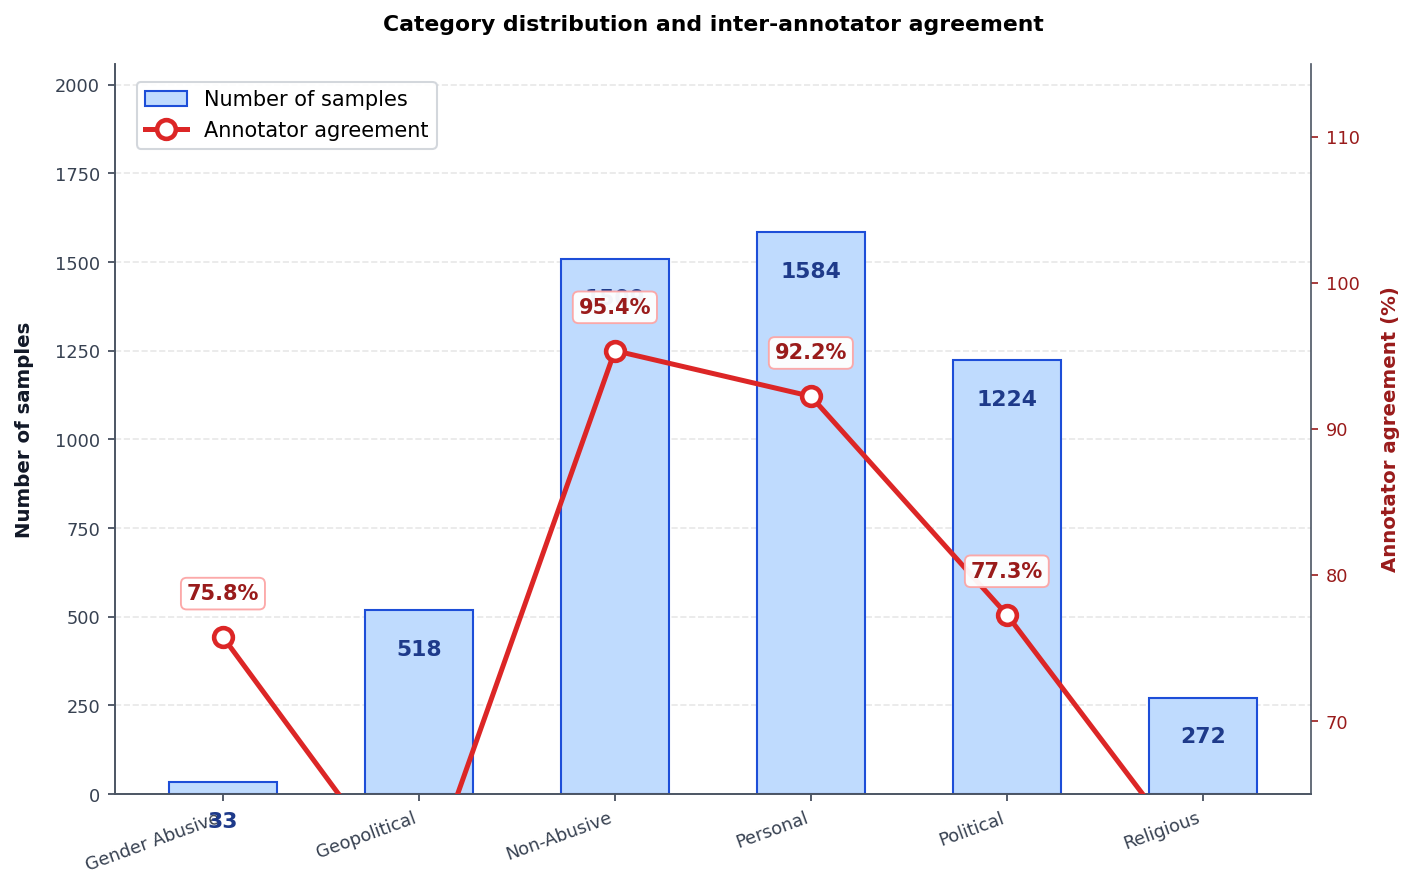

In [6]:
from sklearn.metrics import precision_recall_fscore_support

support = cm.sum(axis=1)
agreement = np.diag(cm) / support

metrics_df = pd.DataFrame({
    "Category": labels,
    "Samples": support,
    "Agreement": agreement
})

fig, ax1 = plt.subplots(figsize=(9.5, 6.0))

x = np.arange(len(labels))
width = 0.55

# ---------------- Bars: sample counts ----------------
bars = ax1.bar(
    x,
    metrics_df["Samples"],
    width=width,
    color="#bfdbfe",
    edgecolor="#1d4ed8",
    linewidth=1.0,
    label="Number of samples",
    zorder=2
)

# Put count labels inside the bars, near the top
for bar, value in zip(bars, metrics_df["Samples"]):
    ax1.annotate(
        f"{int(value)}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, -14),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=10.5,
        fontweight="bold",
        color="#1e3a8a",
        zorder=4
    )

ax1.set_ylabel("Number of samples", fontweight="bold", labelpad=10)
ax1.set_ylim(0, max(support) * 1.30)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=20, ha="right")
ax1.grid(axis="y", linestyle="--", alpha=0.30, zorder=0)
ax1.set_axisbelow(True)

# ---------------- Line: agreement ----------------
ax2 = ax1.twinx()

line = ax2.plot(
    x,
    metrics_df["Agreement"] * 100,
    marker="o",
    markersize=9,
    markerfacecolor="white",
    markeredgecolor="#dc2626",
    markeredgewidth=2.2,
    linewidth=2.4,
    color="#dc2626",
    label="Annotator agreement",
    zorder=5
)[0]

# Agreement labels: use annotation boxes with enough vertical offset
for xi, value in zip(x, metrics_df["Agreement"] * 100):
    ax2.annotate(
        f"{value:.1f}%",
        xy=(xi, value),
        xytext=(0, 16),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#991b1b",
        bbox=dict(
            boxstyle="round,pad=0.28",
            facecolor="white",
            edgecolor="#fca5a5",
            linewidth=0.9,
            alpha=0.95
        ),
        zorder=6
    )

ax2.set_ylabel("Annotator agreement (%)", fontweight="bold", color="#991b1b", labelpad=10)
ax2.set_ylim(65, 115)
ax2.tick_params(axis="y", colors="#991b1b")

# ---------------- Legend ----------------
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left",
    bbox_to_anchor=(0.01, 0.99),
    frameon=True,
    framealpha=0.95,
    edgecolor="#d1d5db",
    fontsize=10
)

ax1.set_title(
    "Category distribution and inter-annotator agreement",
    fontweight="bold",
    pad=16
)

sns.despine(ax=ax1)
sns.despine(ax=ax2, right=False)

plt.tight_layout()
plt.savefig("category_distribution_agreement.png", dpi=600, bbox_inches="tight")
plt.savefig("category_distribution_agreement.pdf", bbox_inches="tight")
plt.show()

c:\Users\USER\miniconda3\envs\ai_ml\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


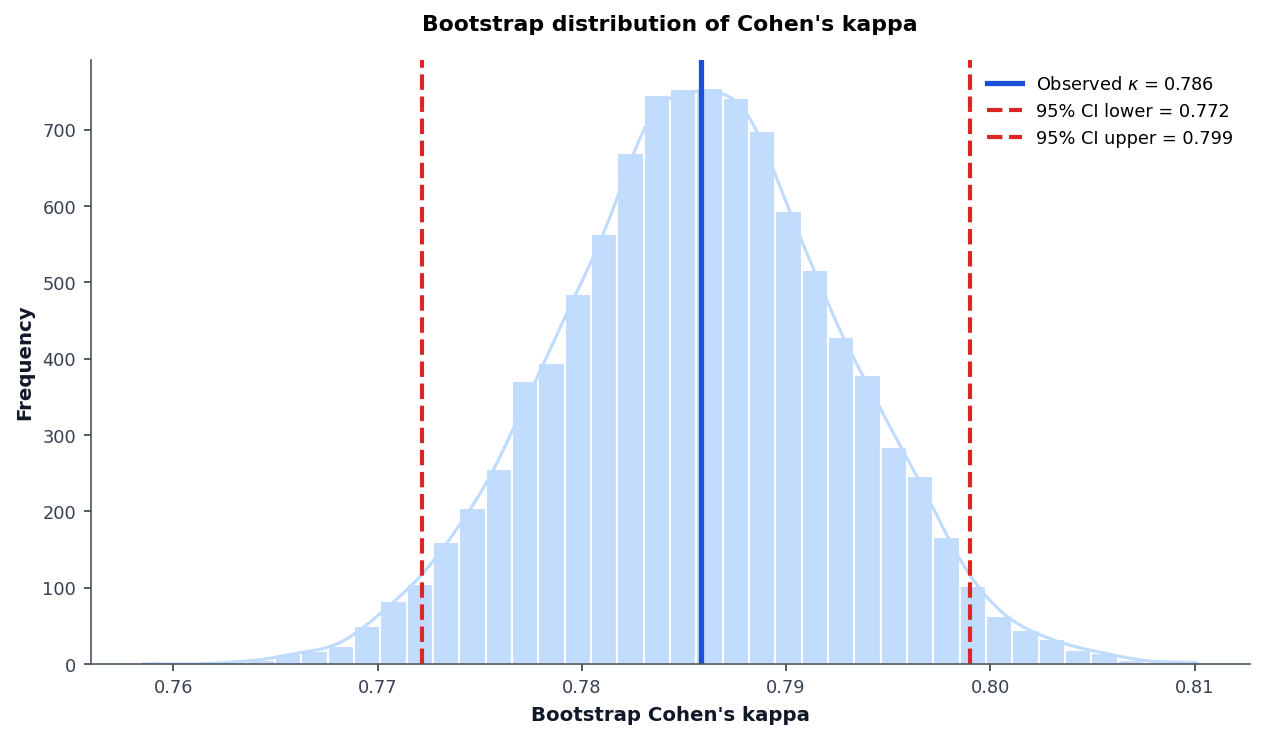

Kappa = 0.7858
Bootstrap 95% CI = [0.7722, 0.7990]


In [8]:
from sklearn.metrics import cohen_kappa_score

rng = np.random.default_rng(42)
n = len(y_true)
boot_kappas = []

for _ in range(10000):
    idx = rng.integers(0, n, size=n)
    yt, yp = y_true[idx], y_pred[idx]

    if len(set(yt)) < 2 or len(set(yp)) < 2:
        continue

    boot_kappas.append(cohen_kappa_score(yt, yp))

ci_low, ci_high = np.percentile(boot_kappas, [2.5, 97.5])
kappa = cohen_kappa_score(y_true, y_pred)

plt.figure(figsize=(8.5, 5))

sns.histplot(
    boot_kappas,
    bins=40,
    kde=True,
    color="#bfdbfe",
    edgecolor="white",
    alpha=0.95
)

plt.axvline(
    kappa,
    color="#1d4ed8",
    linestyle="-",
    linewidth=2.5,
    label=f"Observed $\\kappa$ = {kappa:.3f}"
)

plt.axvline(
    ci_low,
    color="#dc2626",
    linestyle="--",
    linewidth=2,
    label=f"95% CI lower = {ci_low:.3f}"
)

plt.axvline(
    ci_high,
    color="#dc2626",
    linestyle="--",
    linewidth=2,
    label=f"95% CI upper = {ci_high:.3f}"
)

plt.xlabel("Bootstrap Cohen's kappa", fontweight="bold")
plt.ylabel("Frequency", fontweight="bold")
plt.title(
    "Bootstrap distribution of Cohen's kappa",
    fontweight="bold",
    pad=14
)

plt.legend(frameon=False)
sns.despine()

plt.tight_layout()
plt.savefig("bootstrap_kappa_distribution.png", dpi=600, bbox_inches="tight")
plt.savefig("bootstrap_kappa_distribution.pdf", bbox_inches="tight")
plt.show()

print(f"Kappa = {kappa:.4f}")
print(f"Bootstrap 95% CI = [{ci_low:.4f}, {ci_high:.4f}]")